# Multi-agent marketing adviser for Airbnb concierge services in Bordeaux
### M2 Quantitative Marketing project, topic 4

When a concierge service takes on a new property, it has to analyse the market, choose a target and a price, then write the listing. Our product hypothesis is that separate tools can make these decisions harder to coordinate.
We want to help concierge services prepare a new property for the market by connecting market analysis, positioning and listing creation in a workflow controlled by the property manager.

Five specialised roles share one property file. The Analyst, Strategist, Creative and Validator call Gemini. The Planner uses Python to prepare and coordinate the work, and can call Gemini to read a free text description. The manager approves the strategy and the final output.

| Agent | Role | Output |
|---|---|---|
| Planner | Reads the request, extracts the property features, coordinates the agents | Property profile, log |
| Analyst | Calls the data tools: comparables, price model, availability, reviews | Evidence brief with sources |
| Strategist | Segmentation, targeting, positioning, price | Strategy backed by the evidence |
| Creative | Turns the strategy into execution | Listing, campaign, photo directions, social post |
| Validator | Rule checks and LLM review | Approval, or work sent back to the right agent |

**Data:** Inside Airbnb, Bordeaux, snapshot of 17 September 2026 (CC BY 4.0 licence).

**Outline:** settings, loading, exploration, cleaning, features, outliers, calendar, reviews, market, literature, price model, image, agents, demo, evaluation, interface, conclusion.


In [35]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.metrics import make_scorer
from sklearn.linear_model import LinearRegression, LassoCV, HuberRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
np.random.seed(42)

## 1. Settings

| Setting | Value | Role |
|---|---|---|
| `USE_LLM` | True / False | Turns Gemini on. Without Gemini, each agent applies its rule-based fallback. |
| `GEMINI_MODEL` | `gemini-3.5-flash-lite` | Model used. |
| `BORDEAUX_CENTRE` | (44.8425, -0.5745) | Grand Théâtre, for the distance to the centre. |
| `RADII_KM` | 1, 2, 3 km | Search radius for comparables, widened if needed. |
| `MIN_COMPARABLES`, `N_TOP_COMPARABLES` | 10, 20 | Minimum number of comparables, and number of most similar ones kept. |
| `SIMILARITY_WEIGHTS` | 0.4 / 0.2 / 0.2 / 0.2 | Weights: location, size, amenities, availability. |
| `MAX_QUOTE_NIGHTS` | 27 | Quotes for 28 nights or more are excluded. |
| `IQR_FACTOR`, `ROBUST_Z` | 1.5 and 3.5 | Outlier thresholds. |
| `MAX_REVISIONS` | 2 | Maximum number of times the Validator can send work back. |


In [36]:
# skip-in-space
!pip install -q google-genai shap gradio sentence-transformers sentencepiece protobuf

'pip' n'est pas reconnu en tant que commande interne
ou externe, un programme ex�cutable ou un fichier de commandes.


In [37]:
USE_LLM = True                    # True once GEMINI_API_KEY is stored in Colab's Secrets panel
GEMINI_MODEL = "gemini-3.5-flash-lite"

BORDEAUX_CENTRE = (44.8425, -0.5745)
RADII_KM = [1.0, 2.0, 3.0]
MIN_COMPARABLES = 10
N_TOP_COMPARABLES = 20
SIMILARITY_WEIGHTS = {'location': 0.4, 'size': 0.2, 'amenities': 0.2, 'availability': 0.2}
MAX_QUOTE_NIGHTS = 27
IQR_FACTOR = 1.5
ROBUST_Z = 3.5
HORIZON_DAYS = 180
COMPETITION_THRESHOLDS = (0.3, 0.7)
COMPETITION_ADJUSTMENT = (1.10, 0.95)
MAX_REVISIONS = 2
USE_IMAGE_ANALYSIS = False

# Hugging Face Space: the same notebook runs as an app (section 16); FAST_MODE skips the long grid searches
IN_SPACE = bool(os.environ.get('SPACE_ID'))
FAST_MODE = IN_SPACE

## 2. Loading the data

The `listings`, `calendar` and `reviews` files are read directly as `.csv.gz`. Reviews are read with quotes respected, because comments contain commas: otherwise more than half of the reviews would be lost.


In [38]:
import glob
def read_file(name, **options):
    candidates = sorted(p for p in glob.glob(f"{name}*") if p.endswith(('.csv', '.gz')))
    if not candidates:
        raise FileNotFoundError(f"No {name}.csv(.gz) file found: put it in the notebook's folder.")
    path = candidates[0]
    try:
        df = pd.read_csv(path, low_memory=False, **options)
    except Exception as e:
        print(f"Standard read failed for {path} ({e}). Tolerant read…")
        df = pd.read_csv(path, engine='python', on_bad_lines='skip', **options)
    print(f"{path}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    return df

listings_raw = read_file("C:/Users/aubie/OneDrive/Bureau/Quantitative_Marketing/listings.csv")
calendar_raw = read_file("C:/Users/aubie/OneDrive/Bureau/Quantitative_Marketing/calendar.csv")
reviews_raw  = read_file("C:/Users/aubie/OneDrive/Bureau/Quantitative_Marketing/reviews.csv")

C:/Users/aubie/OneDrive/Bureau/Quantitative_Marketing\listings.csv: 12,063 rows, 90 columns
C:/Users/aubie/OneDrive/Bureau/Quantitative_Marketing\calendar.csv: 4,402,995 rows, 5 columns
C:/Users/aubie/OneDrive/Bureau/Quantitative_Marketing\reviews.csv: 516,990 rows, 6 columns


## 3. Data exploration

Every cleaning choice is based on what this exploration shows.

### 3.1 Columns and missing values


In [39]:
print(f"Listings: {listings_raw.shape[0]:,} | Columns: {listings_raw.shape[1]}")

missing = listings_raw.isnull().mean().sort_values(ascending=False)
empty = missing[missing == 1].index.tolist()
print(f"\nCompletely empty columns ({len(empty)}):", empty)

print("\nOther columns with more than 20% missing values (%):")
print((missing[(missing > 0.2) & (missing < 1)] * 100).round(1).to_string())

print("\nMissing values in the model variables (%):")
print((listings_raw[['bedrooms', 'beds', 'bathrooms_text', 'review_scores_rating', 'amenities',
                     'latitude', 'longitude']].isnull().mean() * 100).round(1).to_string())

Listings: 12,063 | Columns: 90

Completely empty columns (13): ['neighborhood_overview', 'host_since', 'host_response_time', 'host_thumbnail_url', 'host_acceptance_rate', 'host_response_rate', 'host_verifications', 'neighbourhood', 'host_total_listings_count', 'host_neighbourhood', 'calendar_updated', 'instant_bookable', 'bathrooms']

Other columns with more than 20% missing values (%):
source                         63.2
license                        61.1
host_about                     60.3
price_quote_price_per_night    36.0
estimated_revenue_l365d        36.0
price_quote_total_price        36.0
price                          36.0
price_quote_raw                33.0
price_quote_checkout_date      33.0
price_quote_checkin_date       33.0

Missing values in the model variables (%):
bedrooms                 0.2
beds                     1.7
bathrooms_text           0.1
review_scores_rating    15.0
amenities                0.0
latitude                 0.0
longitude                0.0


### 3.2 Listings without a price


In [41]:
no_price = listings_raw['price'].isnull()
print(f"Listings without a price: {no_price.sum():,} ({no_price.mean():.0%})\n")

comparison = pd.DataFrame({
    'No available day over a year': listings_raw.groupby(no_price)['availability_365'].apply(lambda s: (s == 0).mean()),
    'No review in 12 months': listings_raw.groupby(no_price)['number_of_reviews_ltm'].apply(lambda s: (s == 0).mean()),
}).rename(index={False: 'With price', True: 'Without price'})
(comparison * 100).round(0)

Listings without a price: 4,341 (36%)



,No available day over a year,No review in 12 months
price,,
With price,1.0,27.0
Without price,83.0,76.0


### 3.3 How the price is measured

The price is a quote for a specific stay, whose dates are in `price_quote_checkin_date` and `price_quote_checkout_date`. Despite the `$` sign, the currency is the euro.


In [43]:
def parse_price(series):
    return pd.to_numeric(series.astype(str).str.replace(r'[\$,]', '', regex=True), errors='coerce')

raw_price = parse_price(listings_raw['price'])
print("Currency in the quote:", listings_raw['price_quote_raw'].dropna().str.extract(r'"currency": "(\w+)"')[0].value_counts().to_dict())
print("\nPrice per night (€):")
print(raw_price.describe(percentiles=[.01, .1, .5, .9, .99]).round(0).to_string())

checkin = pd.to_datetime(listings_raw['price_quote_checkin_date'], errors='coerce')
checkout = pd.to_datetime(listings_raw['price_quote_checkout_date'], errors='coerce')
quote_nights = (checkout - checkin).dt.days

stay = pd.cut(quote_nights, [0, 3, 6, 27, 400], labels=['1 to 3 nights', '4 to 6 nights', '7 to 27 nights', '28 nights or more'])
print("\nPrice by length of the quoted stay:")
print(pd.DataFrame({'listings': raw_price.groupby(stay, observed=True).count(),
                    'median price (€)': raw_price.groupby(stay, observed=True).median().round(0)}).to_string())
print(f"\nQuote check-in date: from {(checkin - pd.Timestamp('2026-09-17')).dt.days.min():.0f} "
      f"to {(checkin - pd.Timestamp('2026-09-17')).dt.days.max():.0f} days after data collection")

Currency in the quote: {'EUR': 7742}

Price per night (€):
count     7722.0
mean       152.0
std        219.0
min          8.0
1%          30.0
10%         50.0
50%        108.0
90%        293.0
99%        703.0
max      11499.0

Price by length of the quoted stay:
                   listings  median price (€)
1 to 3 nights          6099             108.0
4 to 6 nights           771             144.0
7 to 27 nights          376             152.0
28 nights or more       476              60.0

Quote check-in date: from 2 to 364 days after data collection


### 3.4 Calendar


In [44]:
print("Calendar columns:", list(calendar_raw.columns))
calendar_dates = pd.to_datetime(calendar_raw['date'])
print(f"Period: from {calendar_dates.min().date()} to {calendar_dates.max().date()}")

active = set(listings_raw.loc[~no_price, 'id'])
cal_active = calendar_raw[calendar_raw['listing_id'].isin(active)]
share_blocked = (cal_active['available'] == 'f').groupby(cal_active['listing_id']).mean()
print(f"Active listings never available over the year: {(share_blocked == 1).mean():.1%}")
print(f"Active listings whose minimum stay varies with dates: "
      f"{(cal_active.groupby('listing_id')['minimum_nights'].nunique() > 1).mean():.0%}")

# Two occupancy measures: calendar (unavailable days, next 6 months) and Inside Airbnb (reviews, last 12 months)
near = cal_active[pd.to_datetime(cal_active['date']) < calendar_dates.min() + pd.Timedelta(days=HORIZON_DAYS)]
occ_calendar = (near['available'] == 'f').groupby(near['listing_id']).mean()
occ_inside = (listings_raw.set_index('id')['estimated_occupancy_l365d'] / 365).reindex(occ_calendar.index)
print(f"\nMedian occupancy, calendar (unavailable days): {occ_calendar.median():.0%}")
print(f"Median occupancy, Inside Airbnb (estimated from reviews): {occ_inside.median():.0%}")
print(f"Correlation between the two measures: {occ_calendar.corr(occ_inside):.2f}")

Calendar columns: ['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']
Period: from 2026-09-19 to 2027-09-18
Active listings never available over the year: 0.0%
Active listings whose minimum stay varies with dates: 23%

Median occupancy, calendar (unavailable days): 28%
Median occupancy, Inside Airbnb (estimated from reviews): 8%
Correlation between the two measures: -0.05


### 3.5 Reviews


In [45]:
print(f"Reviews: {len(reviews_raw):,} | Empty comments: {reviews_raw['comments'].isnull().sum()}")
print(f"Period: from {reviews_raw['date'].min()} to {reviews_raw['date'].max()}")

Reviews: 516,990 | Empty comments: 8
Period: from 2012-01-04 to 2026-09-19


### What the exploration shows

**12,063 listings and 90 columns**, 13 of them empty.

**36% of listings have no price.** 83% have no available day over the year, against 1% for listings with a price. This association does not establish why their price is missing. They are excluded because the pricing target is unavailable.

**The price includes long-stay discounts.** Quotes for 28 nights or more have a median price of €60, against €108 for 1 to 3 nights: they are excluded.

**The calendar contains neither prices nor bookings**, only free or not free. It is therefore used to measure availability on given dates.

**Occupancy comes from Inside Airbnb**, estimated from reviews. Calendar unavailability cannot distinguish a booking from a host-blocked date.

Other missing values are rare, except the rating (15%, listings without reviews).



## 4. Cleaning

1. Convert the price to a number.
2. Remove listings without a price.
3. Remove quotes for 28 nights or more.
4. Keep positive prices and complete essential columns.

No fixed price threshold is applied: a price is only extreme compared with the property. This is handled in section 6.


In [46]:
listings = listings_raw.copy()
listings['price'] = parse_price(listings['price'])
listings['quote_nights'] = quote_nights
steps = {'Listings at the start': len(listings)}

listings = listings.dropna(subset=['price', 'latitude', 'longitude'])
steps['With a price'] = len(listings)

listings = listings[listings['quote_nights'] <= MAX_QUOTE_NIGHTS]
steps[f'Quotes of {MAX_QUOTE_NIGHTS} nights or less'] = len(listings)

essential_columns = ['id', 'room_type', 'accommodates', 'neighbourhood_cleansed', 'amenities']
listings = listings[listings['price'] > 0].dropna(subset=essential_columns).copy()
steps['Positive price, essential columns complete'] = len(listings)

pd.Series(steps, name='listings').to_frame()

,listings
Listings at the start,12063
With a price,7722
Quotes of 27 nights or less,7246
"Positive price, essential columns complete",7246


### Result

12,063 listings at the start, 7,722 with a price, then **7,246** after removing quotes for 28 nights or more.


## 5. Features extracted automatically

**Counts rather than yes/no**: number of amenities, safety items and bathrooms.

**Safety**: smoke alarm, carbon monoxide alarm, fire extinguisher, first aid kit.

**Kitchen type**: separate or open, from the description.

**Distance to the centre** in km, computed from latitude and longitude.


All these features are computed by code, with no manual input.


In [47]:
def parse_amenities(text):
    try:
        return [a.lower() for a in json.loads(text)]
    except Exception:
        return []

SAFETY = ['smoke alarm', 'carbon monoxide alarm', 'fire extinguisher', 'first aid kit']

def count_items(amenities, items):
    return sum(any(i in a for a in amenities) for i in items)

def has_amenity(amenities, word):
    return int(any(word in a for a in amenities))

def kitchen_type(description, amenities):
    # Keywords stay in French and English, since descriptions are written in both languages
    d = str(description).lower()
    if any(w in d for w in ['cuisine séparée', 'cuisine separee', 'cuisine indépendante', 'cuisine independante',
                            'separate kitchen', 'closed kitchen', 'cuisine fermée', 'cuisine fermee']):
        return 'separate'
    if any(w in d for w in ['kitchenette', 'cuisine ouverte', 'cuisine américaine', 'cuisine americaine',
                            'open kitchen', 'open-plan kitchen', 'coin cuisine']):
        return 'open'
    if has_amenity(amenities, 'kitchen'):
        return 'kitchen (type unknown)'
    return 'no kitchen'

def n_bathrooms(text):
    # "1.5 baths" -> 1.5 ; "Half-bath" -> 0.5
    t = str(text).lower()
    if 'half' in t and not re.search(r'\d', t):
        return 0.5
    m = re.search(r'(\d+(\.\d+)?)', t)
    return float(m.group(1)) if m else np.nan

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

am = listings['amenities'].apply(parse_amenities)
listings['amenity_list']     = am
listings['n_amenities']      = am.apply(len)
listings['n_safety']         = am.apply(lambda a: count_items(a, SAFETY))
listings['parking']          = am.apply(lambda a: has_amenity(a, 'parking'))
listings['air_conditioning'] = am.apply(lambda a: has_amenity(a, 'air conditioning'))
listings['washer']           = am.apply(lambda a: has_amenity(a, 'washer'))
listings['workspace']        = am.apply(lambda a: has_amenity(a, 'workspace'))
listings['wifi']             = am.apply(lambda a: has_amenity(a, 'wifi'))
listings['kitchen']          = [kitchen_type(d, a) for d, a in zip(listings['description'], am)]
listings['separate_kitchen'] = (listings['kitchen'] == 'separate').astype(int)
listings['n_bathrooms']      = listings['bathrooms_text'].apply(n_bathrooms)
listings['dist_centre_km']   = haversine_km(listings['latitude'], listings['longitude'], *BORDEAUX_CENTRE)
listings['superhost']        = (listings['host_is_superhost'] == 't').astype(int)
listings['occupancy']        = listings['estimated_occupancy_l365d'] / 365

for col in ['bedrooms', 'beds', 'n_bathrooms']:
    listings[col] = listings[col].fillna(listings[col].median())

listings[['n_amenities', 'n_safety', 'parking', 'kitchen', 'n_bathrooms', 'dist_centre_km', 'occupancy']].head()

,n_amenities,n_safety,parking,kitchen,n_bathrooms,dist_centre_km,occupancy
1,0,0,0,no kitchen,1.5,0.956343,0.493151
2,0,0,0,no kitchen,1.5,0.783460,0.246575
3,0,0,0,no kitchen,1.0,0.605349,0.197260
4,0,0,0,no kitchen,1.0,0.271300,0.698630
5,0,0,0,no kitchen,1.0,3.678601,0.301370


In [48]:
print("Kitchen type:")
print(listings['kitchen'].value_counts().to_string())
print("\nNumber of safety items (0 to 4), in %:")
print((listings['n_safety'].value_counts(normalize=True).sort_index() * 100).round(0).to_string())

Kitchen type:
kitchen
no kitchen    6827
open           391
separate        28

Number of safety items (0 to 4), in %:
n_safety
0    100.0


### Reading

**Kitchen**: the type remains unknown for 84% of properties, because descriptions rarely mention it. The optional image model can suggest a category that needs confirmation. Image inference is disabled in the lightweight Streamlit deployment.

**Safety**: 44% of properties declare a single item, without verifying the equipment type or regulatory compliance from that count alone, and 17% none.



## 6. Outliers

A price of €400 is normal for a house for 10 and absurd for a studio. Each price is therefore judged against the property, with three rules:

1. **Price per m²**, when the surface appears in the description, compared with properties of the same type.
2. **Price per guest**, compared with properties of the same type and capacity.
3. **Price given size and amenities**, from a robust (Huber) regression.

A listing is removed if its price per m² is extreme, or if it is extreme both per guest and according to the regression.


In [49]:
SURFACE_PATTERN = r'(\d{2,3}(?:[.,]\d)?)\s?(?:m²|m2|sqm|sq m|square met|mètres carrés|metres carres|m\b)'

def extract_surface(text):
    m = re.search(SURFACE_PATTERN, str(text).lower())
    if not m:
        return np.nan
    value = float(m.group(1).replace(',', '.'))
    return value if 9 <= value <= 500 else np.nan

def iqr_outlier(values, groups, factor=IQR_FACTOR):
    q1 = values.groupby(groups).transform(lambda s: s.quantile(0.25))
    q3 = values.groupby(groups).transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    return (values < q1 - factor * iqr) | (values > q3 + factor * iqr)

listings['surface_m2'] = listings['description'].apply(extract_surface)
listings['price_per_m2'] = listings['price'] / listings['surface_m2']
listings['price_per_guest'] = listings['price'] / listings['accommodates']
listings['size_group'] = pd.cut(listings['accommodates'], [0, 2, 4, 6, 100], labels=['1-2', '3-4', '5-6', '7+'])
print(f"Surface found in the description: {listings['surface_m2'].notna().mean():.0%} of listings "
      f"(median {listings['surface_m2'].median():.0f} m²)")

# Rule 1: price per m², same room type (only where the surface is known)
known = listings['surface_m2'].notna()
rule_m2 = pd.Series(False, index=listings.index)
rule_m2[known] = iqr_outlier(np.log(listings.loc[known, 'price_per_m2']), listings.loc[known, 'room_type'])

# Rule 2: price per guest, same room type and size group
rule_guest = iqr_outlier(np.log(listings['price_per_guest']),
                         [listings['room_type'], listings['size_group'].astype(str)])

# Rule 3: price given size and amenities (robust regression)
Z = pd.concat([listings[['accommodates', 'bedrooms', 'n_bathrooms', 'n_amenities']],
               pd.get_dummies(listings['room_type'], drop_first=True, dtype=float)], axis=1).astype(float)
huber = HuberRegressor(max_iter=500).fit(StandardScaler().fit_transform(Z), np.log(listings['price']))
residual = np.log(listings['price']) - huber.predict(StandardScaler().fit_transform(Z))
robust_z = (residual - residual.median()) / (1.4826 * (residual - residual.median()).abs().median())
rule_model = robust_z.abs() > ROBUST_Z

remove = rule_m2 | (rule_guest & rule_model)
summary = pd.Series({
    'Rule 1: extreme price per m²': rule_m2.sum(),
    'Rule 2: extreme price per guest': rule_guest.sum(),
    'Rule 3: extreme given size and amenities': rule_model.sum(),
    'Removed (rule 1, or rules 2 and 3 together)': remove.sum(),
}, name='listings')
print(summary.to_string())

removed = listings[remove]
print(f"\nRemoved listings: prices from €{removed['price'].min():.0f} to €{removed['price'].max():.0f} "
      f"(median €{removed['price'].median():.0f})")
print("Examples:")
print(removed[['room_type', 'accommodates', 'bedrooms', 'n_amenities', 'surface_m2', 'price']]
      .sort_values('price').iloc[[0, 1, 2, -3, -2, -1]].to_string())

listings = listings[~remove].copy()
print(f"\nListings kept: {len(listings):,}")

Surface found in the description: 31% of listings (median 60 m²)
Rule 1: extreme price per m²                   164
Rule 2: extreme price per guest                124
Rule 3: extreme given size and amenities        70
Removed (rule 1, or rules 2 and 3 together)    215

Removed listings: prices from €8 to €11499 (median €131)
Examples:
             room_type  accommodates  bedrooms  n_amenities  surface_m2     price
11209     Private room             1       1.0            0         NaN      8.29
7449      Private room             2       1.0            0         NaN     10.00
11766  Entire home/apt             4       1.0            0       100.0     20.00
8718   Entire home/apt             2       1.0            0         NaN   2903.30
4909   Entire home/apt             4       1.0            0        35.0   3370.50
7456   Entire home/apt             2       1.0            0        30.0  11499.00

Listings kept: 7,031


### Result

Surface found for **31%** of listings (median 60 m²).

**215 listings removed** (3%), with prices from €8 to €11,499.

Expensive but consistent properties are kept.

**7,031 listings** remain for the analysis.



## 7. Calendar: availability and competition

For each day, the calendar shows whether the property is free. From it we derive:

1. **Availability on given dates**: the code identifies comparables marked available for the whole requested stay in the snapshot.
2. **Competitive pressure**: the rule fallback applies a heuristic price adjustment according to available comparables. No causal pricing benefit has been measured.
3. **Minimum stay** used over the period.
4. **A seasonality index**, for information only.


In [50]:
cal = calendar_raw[calendar_raw['listing_id'].isin(listings['id'])].copy()
cal['date'] = pd.to_datetime(cal['date'])
cal['free'] = (cal['available'] == 't').astype(int)
CALENDAR_START = cal['date'].min()

def availability(ids, start, end):
    # For each listing: 1 if it is free EVERY day from start (included) to end (excluded), otherwise 0
    period = cal[(cal['date'] >= pd.Timestamp(start)) & (cal['date'] < pd.Timestamp(end)) & cal['listing_id'].isin(ids)]
    free = period.groupby('listing_id')['free'].min()
    return free.reindex(ids).fillna(0).astype(int)

def minimum_stay(ids, start, end):
    # Minimum stay required by each listing on the first day of the period
    day = cal[(cal['date'] == pd.Timestamp(start)) & cal['listing_id'].isin(ids)]
    return day.set_index('listing_id')['minimum_nights'].reindex(ids)

# Seasonality index (complement): listings neither always free nor always blocked, next 6 months
share_free = cal.groupby('listing_id')['free'].mean()
informative = share_free[(share_free > 0) & (share_free < 1)].index
c6 = cal[cal['listing_id'].isin(informative) & (cal['date'] < CALENDAR_START + pd.Timedelta(days=HORIZON_DAYS))]
by_month = 1 - c6.groupby(c6['date'].dt.to_period('M'))['free'].mean()
season_index = (by_month / by_month.mean()).round(3)
print("Seasonality index (unavailable days, base 1):")
print(season_index.to_string())

# Example: Christmas holidays
xmas_start, xmas_end = '2026-12-19', '2026-12-26'
print(f"\nListings free for the whole week from {xmas_start}: {availability(listings['id'], xmas_start, xmas_end).mean():.0%}")
ms = cal.groupby(cal['date'].between('2026-12-19', '2027-01-03'))['minimum_nights'].mean()
print(f"Average minimum stay: {ms[True]:.1f} nights during the holidays, {ms[False]:.1f} for the rest of the year")

Seasonality index (unavailable days, base 1):
date
2026-09    1.690
2026-10    1.121
2026-11    0.859
2026-12    0.854
2027-01    0.858
2027-02    0.818
2027-03    0.799
Freq: M

Listings free for the whole week from 2026-12-19: 56%
Average minimum stay: 5.1 nights during the holidays, 3.5 for the rest of the year


### Reading

During Christmas week, **57%** of listings are free every day.

The average minimum stay rises from 3.5 nights to **5.1 nights** during the holidays.

Calendar availability can reflect both bookings and host choices. The descriptive seasonality index is not used directly in the price formula. The price is adjusted according to competition on the requested dates instead.



## 8. Reviews: NLP analysis

Keyword search handles negation badly ("not quiet" can be counted as quiet). We therefore use two pretrained multilingual Hugging Face models:

1. **A sentence encoder** (`paraphrase-multilingual-MiniLM-L12-v2`) links each review sentence to an aspect: calm, cleanliness, location, parking, family, work.
2. **A sentiment model** (`twitter-xlm-roberta-base-sentiment`) says whether the sentence is positive, neutral or negative.

The 10 most recent reviews of each listing are analysed on GPU (3 on CPU). The results are saved in `nlp_reviews_cache_v2.csv`, so a later run reloads them instead of running the models again.

If the models cannot be loaded, the code keeps a keyword method and prints the reason. Read the `Method:` line before the table: its second column is always called `NLP (%)`, even when the keyword method is used. This fallback is separate from the Gemini fallback of the agents.


In [51]:
reviews = reviews_raw.copy()
reviews['listing_id'] = pd.to_numeric(reviews['listing_id'], errors='coerce')
reviews = reviews.dropna(subset=['listing_id', 'comments']).copy()
reviews['listing_id'] = reviews['listing_id'].astype('int64')
reviews = reviews[reviews['listing_id'].isin(listings['id'])]
reviews = reviews.drop(columns=[c for c in ['reviewer_id', 'reviewer_name'] if c in reviews.columns])
print(f"Reviews kept: {len(reviews):,}")

USE_NLP_MODELS = True            # False: keyword method only (fast, but biased)
REVIEWS_PER_LISTING = 10         # most recent reviews analysed per listing (reduced automatically without GPU)
EMBED_MODEL = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'   # multilingual sentence encoder
SENTIMENT_MODEL = 'cardiffnlp/twitter-xlm-roberta-base-sentiment'             # multilingual sentiment (neg / neu / pos)
# Minimum cosine similarity between a sentence and an aspect, stricter for aspects that generic praise resembles
ASPECT_THRESHOLD = {'calm_noise': 0.45, 'cleanliness': 0.55, 'location': 0.45,
                    'parking': 0.55, 'family': 0.60, 'work': 0.60}
NLP_CACHE = 'nlp_reviews_cache_v2.csv'   #  results computed with the corrected settings

# Same theme names as before, so the rest of the notebook (agents, interface) is unchanged
THEMES = {
    'quiet':       ['calme', 'tranquille', 'quiet', 'peaceful'],
    'noise':       ['bruit', 'bruyant', 'noisy', 'noise'],
    'cleanliness': ['propre', 'clean', 'spotless'],
    'location':    ['emplacement', 'bien situé', 'bien situe', 'great location', 'well located', 'central'],
    'parking':     ['parking', 'se garer', 'stationnement'],
    'family':      ['enfant', 'famille', 'kids', 'family', 'children'],
    'work':        ['télétravail', 'teletravail', 'bureau', 'workspace', 'work trip', 'business'],
}
# For these themes explicit keywords are reliable (guests clearly name the topic),
# so a review counts if the keywords OR the NLP models find it
MENTION_THEMES = ['parking', 'family', 'work', 'cleanliness']
# Aspects are defined by MEANING (example sentences in English and French), not by single words
ASPECTS = {
    'calm_noise':  ["The apartment is very quiet and peaceful at night.", "Le logement est très calme et tranquille.",
                    "It was very noisy, we heard the street all night.", "Il y avait beaucoup de bruit la nuit."],
    'cleanliness': ["The flat was spotless, the bathroom and the kitchen were perfectly clean.", "Logement impeccable, d'une propreté irréprochable.",
                    "The bathroom was dirty and the sheets were stained.", "Le ménage n'avait pas été fait, c'était sale."],
    'location':    ["Great location, close to the city centre, shops and the tram.", "Très bien situé, proche du centre et des commerces.",
                    "The location is far from everything.", "C'est loin du centre."],
   'parking':     ["We parked the car for free right in front of the building.", "Il y a une place de parking privée dans la résidence.",
                    "Finding a parking space in the street was very difficult.", "Le stationnement est payant et difficile dans le quartier."],
    'family':      ["We travelled with our two young children and the kids loved it.", "Nous étions en famille avec des enfants en bas âge.",
                    "There was a cot and a high chair for our baby.", "Il y avait un lit bébé et une chaise haute pour notre fils."],
    'work':        ["I stayed here for a business trip and worked remotely from the flat.", "Séjour professionnel, j'ai pu télétravailler au bureau.",
                    "There is a desk and fast wifi for video calls.", "Un espace de travail avec un bureau, pratique pour mes réunions en visio."],
}
# theme = (aspect, required sentiment); None = the guest talks about it, whatever the sentiment
THEME_RULES = {'quiet': ('calm_noise', 'positive'), 'noise': ('calm_noise', 'negative'),
               'cleanliness': ('cleanliness', 'positive'), 'location': ('location', 'positive'),
               'parking': ('parking', None), 'family': ('family', None), 'work': ('work', None)}


def keyword_themes(df):
    text = df['comments'].astype(str).str.lower()
    out = pd.DataFrame(index=df.index)
    for theme, words in THEMES.items():
        out[theme] = text.str.contains('|'.join(words), regex=True).astype(int)
    return out


def nlp_themes(df):
    import torch
    from sentence_transformers import SentenceTransformer
    from transformers import pipeline
    device = 0 if torch.cuda.is_available() else -1

    # 1. Split each review into sentences (an opinion is usually expressed in one sentence)
    sent = (df['comments'].astype(str).str.replace('<br/>', ' ', regex=False)
            .str.split(r'(?<=[.!?])\s+|\n+', regex=True).explode().str.strip())
    sent = sent[sent.str.len().between(12, 400)]
    review_id = sent.index.values                     # which review each sentence comes from
    sent = sent.reset_index(drop=True)
    print(f"{len(sent):,} sentences to analyse ({'GPU' if device == 0 else 'CPU: slower'})")

    # 2. Sentence embeddings → similarity with each aspect (meaning, any language)
    encoder = SentenceTransformer(EMBED_MODEL, device='cuda' if device == 0 else 'cpu')
    s_emb = encoder.encode(sent.tolist(), batch_size=256, normalize_embeddings=True, show_progress_bar=True)
    about = {}
    for aspect, examples in ASPECTS.items():
        centre = encoder.encode(examples, normalize_embeddings=True).mean(axis=0)
        about[aspect] = (s_emb @ (centre / np.linalg.norm(centre))) >= ASPECT_THRESHOLD[aspect]
    about = pd.DataFrame(about)

    # 3. Sentiment only for sentences that talk about at least one aspect
    keep = about.any(axis=1).values
    sentiment = np.array(['neutral'] * len(sent), dtype=object)
    if keep.any():
        clf = pipeline('sentiment-analysis', model=SENTIMENT_MODEL, device=device, truncation=True, max_length=128)
        sentiment[keep] = [l['label'].lower() for l in clf(sent[keep].tolist(), batch_size=64)]

    # 4. From sentences to reviews: a review mentions a theme if one of its sentences does
    flags = pd.DataFrame({theme: (about[aspect].values & ((sentiment == needed) if needed else True)).astype(int)
                          for theme, (aspect, needed) in THEME_RULES.items()})
    out = flags.groupby(review_id).max().reindex(df.index, fill_value=0)
    score = pd.Series(sentiment).map({'positive': 1, 'neutral': 0, 'negative': -1}).values
    out['sentiment'] = pd.Series(score[keep]).groupby(review_id[keep]).mean().reindex(df.index)
    return out


# Sample: the most recent reviews of each listing
reviews = reviews.sort_values('date')
method = 'keywords'
if USE_NLP_MODELS:
    try:
        if os.path.exists(NLP_CACHE):
            cache = pd.read_csv(NLP_CACHE, index_col=0)
            reviews = reviews.loc[reviews.index.intersection(cache.index)]
            nlp = cache.loc[reviews.index]
            print(f"NLP results loaded from {NLP_CACHE}")
        else:
            import torch
            n_per = REVIEWS_PER_LISTING if torch.cuda.is_available() else min(REVIEWS_PER_LISTING, 3)
            reviews = reviews.groupby('listing_id').tail(n_per)
            nlp = nlp_themes(reviews)
            nlp.to_csv(NLP_CACHE)
        method = 'NLP models'
    except Exception as e:
        print("NLP models not available, keyword method used instead:", e)

kw = keyword_themes(reviews)
if method == 'NLP models':
    for theme in THEMES:
        reviews[theme] = nlp[theme].astype(int)
        if theme in MENTION_THEMES:
            reviews[theme] = (reviews[theme] | kw[theme]).astype(int)
    reviews['sentiment'] = nlp['sentiment']
else:
    for theme in THEMES:
        reviews[theme] = kw[theme]
print(f"Method: {method} | reviews analysed: {len(reviews):,}")

listings = listings.drop(columns=[f'reviews_{t}' for t in THEMES] + ['guest_sentiment'], errors='ignore')
themes_by_listing = reviews.groupby('listing_id')[list(THEMES)].mean().add_prefix('reviews_')
listings = listings.merge(themes_by_listing, left_on='id', right_index=True, how='left')
if 'sentiment' in reviews:
    listings = listings.merge(reviews.groupby('listing_id')['sentiment'].mean().rename('guest_sentiment'),
                              left_on='id', right_index=True, how='left')
REVIEW_AVERAGES = themes_by_listing.mean()

# Keywords vs NLP on the same reviews: where the keyword method was biased
comparison = pd.DataFrame({'keywords (%)': kw.mean() * 100, 'NLP (%)': reviews[list(THEMES)].mean() * 100}).round(1)
print(comparison.to_string())
if method == 'NLP models':
    wrong = reviews[(kw['quiet'] == 1) & (reviews['noise'] == 1)]
    print(f"\nReviews counted as 'quiet' by keywords but actually complaining about noise: {len(wrong):,}")
    for c in wrong['comments'].head(3):
        print("  -", str(c)[:160])

Reviews kept: 411,075
NLP models not available, keyword method used instead: No module named 'torch'
Method: keywords | reviews analysed: 411,075
             keywords (%)  NLP (%)
quiet                15.0     15.0
noise                 1.9      1.9
cleanliness          22.2     22.2
location             15.2     15.2
parking               4.3      4.3
family                3.2      3.2
work                  0.2      0.2


In [52]:
# Manual check: random examples of what the NLP adds, and of what it misses, for each theme
for theme in THEMES:
    added = reviews[(reviews[theme] == 1) & (kw[theme] == 0)]
    missed = reviews[(reviews[theme] == 0) & (kw[theme] == 1)]
    print(f"\n=== {theme}: {len(added):,} added by NLP, {len(missed):,} keyword matches not counted")
    for c in added['comments'].sample(min(3, len(added)), random_state=1):
        print('  + ', str(c).replace('<br/>', ' ')[:300])
    for c in missed['comments'].sample(min(3, len(missed)), random_state=1):
        print('  - ', str(c).replace('<br/>', ' ')[:300])


=== quiet: 0 added by NLP, 0 keyword matches not counted

=== noise: 0 added by NLP, 0 keyword matches not counted

=== cleanliness: 0 added by NLP, 0 keyword matches not counted

=== location: 0 added by NLP, 0 keyword matches not counted

=== parking: 0 added by NLP, 0 keyword matches not counted

=== family: 0 added by NLP, 0 keyword matches not counted

=== work: 0 added by NLP, 0 keyword matches not counted


### Reading

The NLP models analysed 157,201 sentences from 52,074 recent reviews on GPU. The final run reloaded these results from the cache. We checked random examples for each theme (next cell) before keeping the settings.

For parking, family, work and cleanliness, guests name the topic explicitly, so a review counts if the keywords **or** the models find it. Quiet, noise and location use the model flags only.

134 reviews counted as "quiet" by keywords are flagged as noise by the NLP. They are cases to inspect, not proven keyword errors: some are mixed, such as "Calme, sauf le chien qui aboie".

**Limits:** we have no labelled accuracy test, and both methods can be wrong. For cleanliness, the keyword rule can also match "not clean". Reviews of neighbouring properties do not prove the qualities of a new property.

The Analyst retrieves themes and excerpts from comparable properties, and the Strategist receives this evidence. The Creative only reads the approved strategy, so the influence of reviews on the listing is indirect. The price model uses numeric review ratings, not text themes.


## 9. The Bordeaux market

Median asking prices and the share of listings belonging to hosts with at least ten listings. These hosts are a potential professional segment whose business type has not been verified.


Listings: 7,031 | Median price: €111 per night
Hosts with 10 or more listings (likely concierge services): 43
Share of listings managed by these hosts: 7.4%


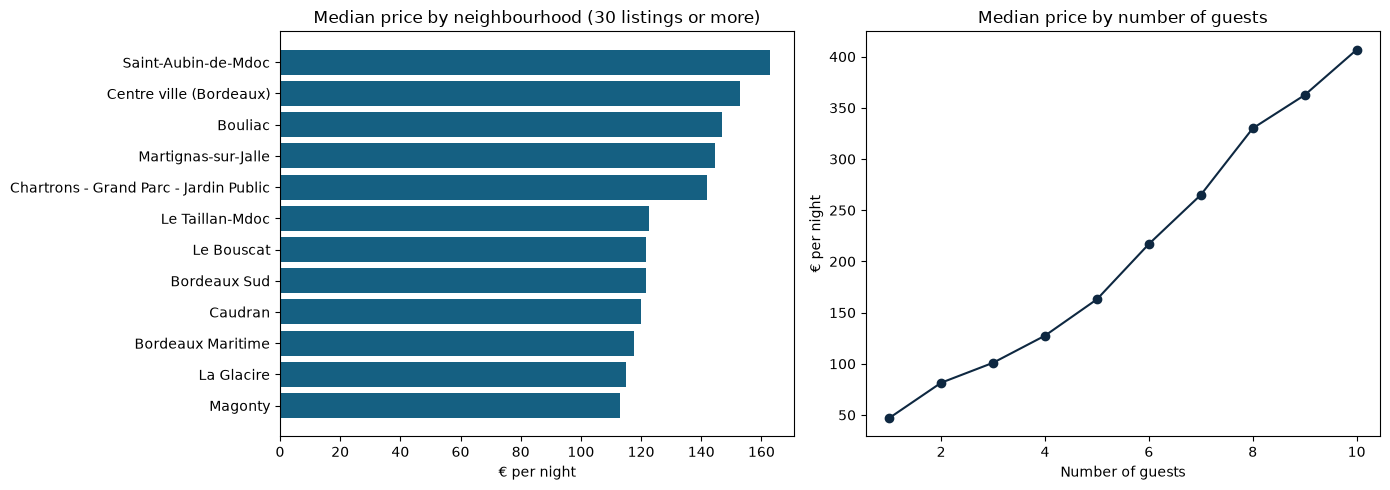

In [53]:
print(f"Listings: {len(listings):,} | Median price: €{listings['price'].median():.0f} per night")
large = listings['calculated_host_listings_count'] >= 10
print(f"Hosts with 10 or more listings (likely concierge services): {listings.loc[large, 'host_id'].nunique()}")
print(f"Share of listings managed by these hosts: {large.mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top = listings.groupby('neighbourhood_cleansed')['price'].agg(['median', 'count'])
top = top[top['count'] >= 30].sort_values('median').tail(12)
axes[0].barh(top.index, top['median'], color='#156082')
axes[0].set_title('Median price by neighbourhood (30 listings or more)')
axes[0].set_xlabel('€ per night')

by_size = listings[listings['accommodates'] <= 10].groupby('accommodates')['price'].median()
axes[1].plot(by_size.index, by_size.values, marker='o', color='#0E2841')
axes[1].set_title('Median price by number of guests')
axes[1].set_xlabel('Number of guests')
axes[1].set_ylabel('€ per night')
plt.tight_layout()
plt.show()

### Reading

We keep **7,031 listings**, with a median asking price of **€111 per night**.

It identifies **43 hosts** with at least ten listings, accounting for **7.4%** of the listings we kept. This does not prove they are concierge companies or that they would buy the product.

The area medians include €166 in Saint-Aubin-de-Médoc, €154 in the city centre and €142 in Chartrons. These are snapshot asking prices. The Analyst uses location and property capacity when searching for comparable listings.


## 10. Literature

**Wang and Nicolau (2017)**, *International Journal of Hospitality Management*: hedonic price model on 33 Airbnb cities.

**Gibbs et al. (2018)**, *Journal of Travel & Tourism Marketing*: same approach on Canadian cities.

**Market tools**: PriceLabs, Beyond, Smart Pricing (dynamic pricing), AirDNA (market data).


These references motivate price modelling. Our prototype also connects pricing evidence with targeting and listing drafts. This does not establish novelty or superiority over existing tools.


## 11. Price model

The agents need a credible price range and an explanation of what drives it.

**80% of the data** is used for training and 5-fold cross-validation, **20%** for a final model holdout. Cleaning and some feature preparation precede this split, so this is not an entirely isolated raw-data evaluation.

Four models are compared: OLS, Lasso, random forest and gradient boosting, the last two tuned by grid search.

The target is the log of the price; errors are expressed in euros.



In [54]:
FEATURES = ['accommodates', 'bedrooms', 'beds', 'n_bathrooms', 'n_amenities', 'n_safety',
            'parking', 'air_conditioning', 'washer', 'workspace', 'separate_kitchen',
            'dist_centre_km', 'superhost']

data = listings.copy()
data['no_rating'] = data['review_scores_rating'].isnull().astype(int)
data['rating'] = data['review_scores_rating'].fillna(data['review_scores_rating'].median())
size_by_neighbourhood = data['neighbourhood_cleansed'].value_counts()
data['neighbourhood_group'] = data['neighbourhood_cleansed'].where(
    data['neighbourhood_cleansed'].map(size_by_neighbourhood) >= 30, 'Other neighbourhoods')

types = pd.get_dummies(data['room_type'], prefix='type', drop_first=True, dtype=int)
neighbourhoods = pd.get_dummies(data['neighbourhood_group'], prefix='nb', drop_first=True, dtype=int)
X = pd.concat([data[FEATURES + ['rating', 'no_rating']], types, neighbourhoods], axis=1).astype(float)
y = np.log(data['price'])

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
dev_ids = data.loc[X_dev.index, 'id']
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def mae_euros(y_true, y_pred):
    return np.mean(np.abs(np.exp(y_true) - np.exp(y_pred)))
MAE_EUROS = make_scorer(mae_euros, greater_is_better=False)

print(f"Training + validation: {len(X_dev):,} listings (5-fold cross-validation) | Final test: {len(X_test):,} listings")

Training + validation: 5,624 listings (5-fold cross-validation) | Final test: 1,407 listings


### 11.1 Tuning the random forest


In [55]:
rf_grid = {
    'max_depth': [None, 15],
    'min_samples_leaf': [1, 3, 5],
    'max_features': [0.33, 0.66],
}
if FAST_MODE:   # Space: only the best combination found in Colab
    rf_grid = {'max_depth': [15], 'min_samples_leaf': [1], 'max_features': [0.33]}
rf_search = GridSearchCV(RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1),
                         rf_grid, cv=cv, scoring=MAE_EUROS, n_jobs=1)
rf_search.fit(X_dev, y_dev)

rf_table = pd.DataFrame(rf_search.cv_results_)[['param_max_depth', 'param_min_samples_leaf', 'param_max_features',
                                                  'mean_test_score', 'std_test_score']]
rf_table.columns = ['max_depth', 'min_samples_leaf', 'max_features', 'validation MAE (€)', 'std (€)']
rf_table['validation MAE (€)'] = -rf_table['validation MAE (€)']
print("Best combination:", rf_search.best_params_)
rf_table.sort_values('validation MAE (€)').round(2)

Best combination: {'max_depth': 15, 'max_features': 0.33, 'min_samples_leaf': 1}


,max_depth,min_samples_leaf,max_features,validation MAE (€),std (€)
6,15,1,0.33,40.51,3.28
7,15,3,0.33,40.51,3.32
8,15,5,0.33,40.53,3.34
2,None,5,0.33,40.56,3.39
1,None,3,0.33,40.67,3.23
11,15,5,0.66,40.88,3.30
5,None,5,0.66,40.93,3.29
10,15,3,0.66,41.00,3.34
4,None,3,0.66,41.07,3.29
9,15,1,0.66,41.24,3.28


### 11.2 Tuning gradient boosting


In [56]:
gb_grid = {
    'learning_rate': [0.05, 0.1],
    'max_depth': [None, 6],
    'max_iter': [300, 600],
}
if FAST_MODE:
    gb_grid = {'learning_rate': [0.05], 'max_depth': [None], 'max_iter': [300]}
gb_search = GridSearchCV(HistGradientBoostingRegressor(min_samples_leaf=20, random_state=42),
                         gb_grid, cv=cv, scoring=MAE_EUROS, n_jobs=1)
gb_search.fit(X_dev, y_dev)

gb_table = pd.DataFrame(gb_search.cv_results_)[['param_learning_rate', 'param_max_depth', 'param_max_iter',
                                                  'mean_test_score', 'std_test_score']]
gb_table.columns = ['learning_rate', 'max_depth', 'max_iter', 'validation MAE (€)', 'std (€)']
gb_table['validation MAE (€)'] = -gb_table['validation MAE (€)']
print("Best combination:", gb_search.best_params_)
gb_table.sort_values('validation MAE (€)').round(2)

Best combination: {'learning_rate': 0.05, 'max_depth': 6, 'max_iter': 300}


,learning_rate,max_depth,max_iter,validation MAE (€),std (€)
2,0.05,6,300,41.03,3.15
0,0.05,None,300,41.29,3.10
3,0.05,6,600,41.47,3.12
6,0.10,6,300,41.69,3.26
1,0.05,None,600,42.01,3.21
4,0.10,None,300,42.32,3.14
7,0.10,6,600,42.37,3.31
5,0.10,None,600,43.35,3.13


### 11.3 Model comparison


In [57]:
candidates = {
    'OLS': LinearRegression(),
    'Lasso': make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=42)),
    'Random forest (tuned)': rf_search.best_estimator_,
    'Gradient boosting (tuned)': gb_search.best_estimator_,
}
rows = {}
for name, model in (list(candidates.items())[2:3] if FAST_MODE else candidates.items()):
    res = cross_validate(model, X_dev, y_dev, cv=cv, scoring={'mae': MAE_EUROS, 'r2': 'r2'})
    rows[name] = {'validation MAE (€)': -res['test_mae'].mean(), 'std (€)': res['test_mae'].std(),
                  'validation R² (log price)': res['test_r2'].mean()}
comparison = pd.DataFrame(rows).T.sort_values('validation MAE (€)')
best_name = comparison.index[0]
print("Model chosen on validation:", best_name)
comparison.round(3)

Model chosen on validation: Random forest (tuned)


,validation MAE (€),std (€),validation R² (log price)
Random forest (tuned),40.509,3.285,0.761
Gradient boosting (tuned),41.032,3.153,0.756
Lasso,42.489,2.659,0.736
OLS,42.538,2.658,0.735


### Reading

The tuned random forest has a validation MAE of **€39.3** per night, against **€39.8** for gradient boosting. The selected random forest uses maximum depth 15 and approximately a third of the features at each split.

Tree-model errors were about €2 lower than OLS and Lasso. Trees can represent nonlinearities and interactions, but these results do not identify the cause of the difference. Tuning and comparison reuse the validation folds, so this is not nested cross-validation.

The separate final model holdout below reports mean error **€38.0**, median error **€21.0**, and **69% coverage** for the nominal 80% interval on 1,407 listings.

The chosen random forest supports price prediction. SHAP describes contributions to its fitted predictions and does not establish causal effects on price.


### 11.4 Price range

Two quantile models (10th and 90th percentiles) give an 80% range for each property.


In [58]:
best_model = candidates[best_name].fit(X_dev, y_dev)
gb_params = {k: v for k, v in gb_search.best_params_.items()}
q_low = HistGradientBoostingRegressor(loss='quantile', quantile=0.10, min_samples_leaf=20, random_state=42, **gb_params).fit(X_dev, y_dev)
q_high = HistGradientBoostingRegressor(loss='quantile', quantile=0.90, min_samples_leaf=20, random_state=42, **gb_params).fit(X_dev, y_dev)

# Final test: used once
test_pred = np.exp(best_model.predict(X_test))
real = np.exp(y_test)
low, high = np.exp(q_low.predict(X_test)), np.exp(q_high.predict(X_test))
neighbourhood_median = data.loc[X_dev.index].groupby('neighbourhood_cleansed')['price'].median()
city_median = data.loc[X_dev.index, 'price'].median()
baseline = data.loc[X_test.index, 'neighbourhood_cleansed'].map(neighbourhood_median).fillna(city_median).values

print(f"FINAL TEST ({len(X_test):,} listings never used before)")
print(f"  Baseline (neighbourhood median): MAE €{np.mean(np.abs(baseline - real)):.1f}")
print(f"  {best_name}: MAE €{np.mean(np.abs(test_pred - real)):.1f} | median error €{np.median(np.abs(test_pred - real)):.1f}")
print(f"  80% range: {np.mean((real >= low) & (real <= high)):.0%} of real prices inside "
      f"(median width €{np.median(high - low):.0f})")

FINAL TEST (1,407 listings never used before)
  Baseline (neighbourhood median): MAE €73.1
  Random forest (tuned): MAE €40.3 | median error €22.4
  80% range: 73% of real prices inside (median width €78)


### 11.5 Explaining a prediction (SHAP)

SHAP splits each prediction into the contributions of the features, for example +6% for air conditioning. The Analyst uses it to justify the price.


In [59]:
try:
    import shap
except ImportError:
    shap = None
    print("SHAP is not installed: run  !pip install shap  in Colab, then rerun this cell.")

tree_for_shap = best_model if best_name.startswith(('Random', 'Gradient')) else gb_search.best_estimator_.fit(X_dev, y_dev)
explainer = shap.TreeExplainer(tree_for_shap) if shap else None

def price_drivers(x_row, top=5):
    # Main contributions to the predicted price, in % (log scale → percentage)
    if explainer is None:
        return []
    values = explainer.shap_values(x_row)[0]
    s = pd.Series(values, index=x_row.columns)
    s = s[s.abs().sort_values(ascending=False).index][:top]
    labels = {c: c.replace('nb_', 'neighbourhood: ').replace('type_', 'room type: ') for c in s.index}
    return [{'feature': labels[c], 'value': float(x_row.iloc[0][c]), 'effect_pct': round(float(np.exp(v) - 1) * 100, 1)}
            for c, v in s.items()]

if explainer is not None:
    sample_shap = explainer.shap_values(X_test.sample(500, random_state=1))
    mean_abs = pd.Series(np.abs(sample_shap).mean(axis=0), index=X.columns).sort_values()
    mean_abs.tail(12).plot(kind='barh', figsize=(8, 5), color='#156082', title='Average impact on the predicted price (SHAP)')
    plt.tight_layout()
    plt.show()
    print("Example, drivers for one test listing:", price_drivers(X_test.iloc[[0]]))

SHAP is not installed: run  !pip install shap  in Colab, then rerun this cell.


### 11.6 OLS as a reference

OLS coefficients describe fitted conditional associations on log price. They do not establish causal effects.


In [60]:
ols = sm.OLS(y_dev, sm.add_constant(X_dev)).fit(cov_type='HC1')
effects = pd.DataFrame({'effect on price (%)': (np.exp(ols.params) - 1) * 100, 'p-value': ols.pvalues}) \
    .drop(index=['const'] + [c for c in X.columns if c.startswith('nb_')])
effects['significant (5%)'] = np.where(effects['p-value'] < 0.05, 'yes', 'no')
effects.round(3)

C:\Users\aubie\AppData\Local\Temp\ipykernel_27900\1623463092.py:1: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols = sm.OLS(y_dev, sm.add_constant(X_dev)).fit(cov_type='HC1')


,effect on price (%),p-value,significant (5%)
accommodates,13.143,0.000,yes
bedrooms,14.799,0.000,yes
beds,-0.067,0.930,no
n_bathrooms,8.669,0.002,yes
n_amenities,-0.000,0.000,yes
n_safety,0.000,0.014,yes
parking,0.000,0.000,yes
air_conditioning,-0.000,0.000,yes
washer,0.000,0.000,yes
workspace,0.000,0.000,yes


## 12. Image analysis (optional)

The CLIP model compares the main photo of the listing with descriptions, for example "a separate kitchen", without any training. Turned off by default (`USE_IMAGE_ANALYSIS = False`) because the model weighs about 600 MB.


In [61]:
IMAGE_LABELS = {
    'separate kitchen': 'a photo of a separate closed kitchen',
    'open kitchen': 'a photo of an open kitchen in a living room',
    'balcony or terrace': 'a photo of a balcony or terrace',
    'living room': 'a photo of a living room',
    'bedroom': 'a photo of a bedroom',
    'fire extinguisher': 'a photo of a fire extinguisher',
}
_clip = None

def analyse_image(url, threshold=0.25):
    global _clip
    if not USE_IMAGE_ANALYSIS or not isinstance(url, str):
        return []
    try:
        import requests, torch
        from io import BytesIO
        from PIL import Image
        from transformers import CLIPModel, CLIPProcessor
        if _clip is None:
            _clip = (CLIPModel.from_pretrained("openai/clip-vit-base-patch32"),
                     CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32"))
        model, processor = _clip
        image = Image.open(BytesIO(requests.get(url, timeout=15).content)).convert("RGB")
        inputs = processor(text=list(IMAGE_LABELS.values()), images=image, return_tensors="pt", padding=True)
        with torch.no_grad():
            probs = model(**inputs).logits_per_image.softmax(dim=1)[0].numpy()
        return [name for name, p in zip(IMAGE_LABELS, probs) if p >= threshold]
    except Exception as e:
        print("Image analysis failed:", e)
        return []

## 13. The agents

### 13.1 How the workflow works

The agents read and update a shared property file. The Analyst calls data tools through Gemini. The Strategist and Creative use their own Gemini instructions. The Validator combines Python checks with a Gemini review. The Planner organises the sequence and can use Gemini to extract a free text request; a completed form does not require this extraction call.

Each response must follow a JSON contract. Every factual claim must use an appropriate source. The file records messages, checks and completed stage snapshots. If a stage raises an error, its partial changes are rolled back. This is local notebook recovery, not persistent server recovery. Streamlit has its separate session runtime.

Demo approvals are explicitly simulated. The interface requires a manager decision before creation and final approval. A revised strategy requires another decision.


In [ ]:
llm_client = None
if USE_LLM:
    # !pip install -q google-genai     (uncomment in Colab if needed)
    from google import genai
    from google.genai import types
    try:
        from google.colab import userdata
        api_key = userdata.get('GEMINI_API_KEY')
    except Exception:
        api_key = os.environ.get('GEMINI_API_KEY')
    if api_key:
        llm_client = genai.Client(api_key=api_key, http_options=types.HttpOptions(timeout=60_000, retry_options=types.HttpRetryOptions(attempts=1)))
        print("Gemini ready:", GEMINI_MODEL)
    else:
        print("No GEMINI_API_KEY found: agents will use their rule-based fallbacks.")
else:
    print("USE_LLM = False: agents will use their rule-based fallbacks.")


def extract_json(text):
    # Gemini sometimes wraps JSON in ``` fences or adds a sentence: keep the outermost {...}
    if not text:
        return None
    start, end = text.find('{'), text.rfind('}')
    if start == -1 or end == -1:
        return None
    try:
        return json.loads(text[start:end + 1])
    except json.JSONDecodeError:
        return None



In [ ]:
# The configuration is shown without an extra API request.
print('Selected Gemini model:', GEMINI_MODEL)
print('Connection success is established only by a completed API call.')


### 13.2 Gemini calls and response checks

The selected model is Gemini 3.5 Flash Lite. Each HTTP request has a 60 second timeout and one SDK attempt. The loop avoids duplicate model names. Quota and service errors are recorded without displaying the key. A per minute limit is different from a daily limit, so rate errors do not automatically disable the model for the whole session.

Gemini 3 uses a low thinking level to limit latency. An invalid Analyst or Creative JSON response receives one correction request. If no usable response remains, the agent uses its clearly labelled rule based fallback. A fallback is not counted as a successful LLM response. A valid JSON object is still subject to stage and source checks.


In [62]:
# Each request uses the selected model and a bounded HTTP timeout.
GEMINI_MODELS = list(dict.fromkeys([GEMINI_MODEL, "gemini-3.5-flash-lite"]))
EXHAUSTED = set()
ACTIVE_MODEL = GEMINI_MODEL
LLM_CALLS = 0

def safe_api_error(error):
    """Expose useful API diagnostics while redacting configured keys and tokens."""
    raw = str(getattr(error, 'message', None) or error)
    for secret in [globals().get('_api_key'), os.environ.get('GEMINI_API_KEY')]:
        if secret:
            raw = raw.replace(str(secret), '[REDACTED]')
    raw = re.sub(r'AIza[0-9A-Za-z_-]{15,}', '[REDACTED]', raw)
    raw = re.sub(r'(?i)((?:[?&]key|api[_-]?key|x-goog-api-key)\s*[:=]\s*[\"\x27]?)[^\s&\"\x27,}]+', r'\1[REDACTED]', raw)
    raw = re.sub(r'(?i)(Bearer\s+)[A-Za-z0-9._~+/-]+', r'\1[REDACTED]', raw)
    code = getattr(error, 'code', None)
    if code is None:
        code = getattr(getattr(error, 'response', None), 'status_code', None)
    name = type(error).__name__
    lower = (name + ' ' + raw).casefold()
    if 'timeout' in lower or 'timed out' in lower or str(code) == '504':
        category = 'timeout'
    elif str(code) == '429': category = 'quota_or_rate_limit'
    elif str(code) in ('401', '403'): category = 'authentication_or_access'
    elif str(code) == '404': category = 'model_or_resource_not_found'
    elif str(code) == '400': category = 'invalid_request_or_key'
    elif str(code) in ('500', '503'): category = 'provider_service_error'
    else: category = 'unclassified'
    return dict(error_type=name, http_code=str(code) if code is not None else None,
                category=category, message=raw[:900])

def ask_llm(system, prompt, tools=None, temperature=0.3, max_tokens=None):
    global ACTIVE_MODEL, LLM_CALLS
    if llm_client is None:
        return None
    for model in [m for m in dict.fromkeys(GEMINI_MODELS) if m not in EXHAUSTED]:
        options = dict(system_instruction=system, temperature=temperature,
                       max_output_tokens=max_tokens, tools=tools or None,
                       automatic_function_calling=types.AutomaticFunctionCallingConfig(maximum_remote_calls=4) if tools else None)
        # Gemini 3 uses levels; do not send this option to the Gemini 2.5 fallback.
        if model.startswith('gemini-3.'):
            options['thinking_config'] = {'thinking_level': 'low'}
        config = types.GenerateContentConfig(**options)
        emit = globals().get('_network_event')
        if emit:
            emit('llm_attempt', model, f'Contacting {model} (60 s per HTTP request).')
        try:
            response = llm_client.models.generate_content(model=model, contents=prompt, config=config)
            usage=getattr(response,'usage_metadata',None)
            record_usage=globals().get('_usage_event')
            if record_usage:
                record_usage(dict(model=model,prompt_tokens=getattr(usage,'prompt_token_count',None),
                                  output_tokens=getattr(usage,'candidates_token_count',None),
                                  total_tokens=getattr(usage,'total_token_count',None),
                                  thinking_tokens=getattr(usage,'thoughts_token_count',None)))
            ACTIVE_MODEL, LLM_CALLS = model, LLM_CALLS + 1
            try:
                text=response.text or ''
            except (AttributeError,ValueError):
                text=''
            answer=extract_json(text)
            if answer is None and emit:
                candidates=getattr(response,'candidates',None) or []
                reason=getattr(candidates[0],'finish_reason',None) if candidates else None
                emit('llm_output_error',model,f'{model} · API response received, but no usable JSON. Finish reason: {reason}.')
            return answer
        except Exception as e:
            details = safe_api_error(e)
            msg = details['message']
            if emit:
                code = details['http_code'] or 'no HTTP code'
                emit('llm_error', model, f"{model} · {details['error_type']} · {code} · {details['category']}: {msg}")
            if '429' in msg or 'RESOURCE_EXHAUSTED' in msg:
                if any(marker in msg.casefold() for marker in ('per day','per_day','requestsperday')):
                    EXHAUSTED.add(model)
                print(f"Quota or rate limit reached for {model} → trying the next model")
            elif details['category'] == 'timeout' or details['http_code'] in ('500', '502', '503', '504', '404') or any(code in msg for code in ['UNAVAILABLE', 'NOT_FOUND']):
                print(f"{model} unavailable right now → trying the next model")
            else:
                print("Gemini call failed:", msg[:200])
                return None
    print("No Gemini model available: the agent uses its rule-based fallback.")
    return None

GROUNDING_POLICY = """
EVIDENCE SCOPE POLICY:
Property claims must be supported by the manager's confirmed property features or highlights (P1).
R1 contains reviews of OTHER comparable properties, not reviews of this property. Use it for
explicitly attributed market observations or research hypotheses, never as proof that this home
is quiet, exceptionally clean, comfortable, bright, or suitable for a particular route.
Do not infer countryside, villa/house type, road access, parking capacity, bed size, crib room,
or a fully equipped kitchen from capacity, neighbourhood, generic room_type or amenity presence.
Wi-Fi presence does not establish reliable/fast Wi-Fi. Parking presence does not establish
multiple spaces. Preserve the supplied neighbourhood spelling; do not expand abbreviations.
Use P1 for property facts, L1 for comparable statistics, M1 for predictions, C1 for calendar,
R1 for comparable reviews. A registered source ID alone does not prove support for a claim.
If evidence is missing, omit the claim from publishable copy or identify the limitation in the
internal strategy. Photo directions are proposed shots, not evidence of existing features.
For validation: inspect EVERY strategy and creative field, including positioning, benefits,
campaign concept, key messages and social post. Report the exact unsupported wording, its
location and a correction instruction to the responsible agent. Do not accept a claim merely
because a previous agent or a registered source label repeated it.
"""


### 13.3 Agent composition and evidence contracts

We implement each role as a Python class. We first define its task, then its system prompt, the information it receives, the tools or resources it can use, and its expected JSON output. The configuration sets temperature and output token limits for its Gemini calls. These are separate roles using an existing model, not five separately trained language models.

The shared property file connects the roles. Each agent reads the relevant sections and writes its result and log. The Analyst can call data tools. The Strategist receives the evidence brief. The Creative receives the approved strategy and confirmed property features. The Validator reads the evidence and outputs to check selected constraints. The Planner mainly prepares form data in Python and can call Gemini for free text extraction.

Memory recalls earlier local cases and does not create new market evidence. Response contracts check selected fields and types. The source registry distinguishes property facts, comparables, model predictions, calendar results and review evidence. The instructions prohibit using neighbouring reviews as proof about the new property. These instructions and checks can still miss violations, as the earlier audit shows.


In [63]:
# Composition of each agent: LLM + memory + tools, with its own LLM parameters.
# temperature: low = factual and stable, high = more creative (and more risk of hallucination)
# max_tokens:  maximum length of the answer (Gemini "thinking" models also count their reasoning in it)
AGENT_CONFIG = {
    'Planner': {
        'role': 'Orchestrator: turns the manager request into a property profile and runs the agents in order',
        'llm': {'temperature': 0.0, 'max_tokens': 1024},
        'memory': 'writes the profile in the shared file; recalls similar past cases from the long-term memory',
        'tools': ['parse_request (Gemini: text → JSON)', 'features_of (data extractor)', 'analyse_image (photo analyser)',
                  'MEMORY.recall (past cases)'],
        'input': 'manager form or description, dates',
        'output': 'property profile (size, amenities, safety, kitchen, distance) + similar past cases',
    },
    'Analyst': {
        'role': 'Market analyst: gathers the evidence, every number comes from a tool',
        'llm': {'temperature': 0.1, 'max_tokens': 4096},
        'memory': 'reads the profile; writes the evidence brief',
        'tools': ['get_property_profile', 'find_comparables (similarity score)', 'predict_price_range (ML model + SHAP)',
                  'check_availability (calendar)', 'summarise_reviews (NLP on reviews)'],
        'input': 'property profile + dates',
        'output': 'evidence brief: comparables, model price and 80% range, availability, guest insights, sourced facts',
    },
    'Strategist': {
        'role': 'Marketing strategist: segmentation, targeting, positioning and price',
        'llm': {'temperature': 0.3, 'max_tokens': 2048},
        'memory': 'reads profile, evidence, past cases and Validator feedback; writes the strategy',
        'tools': ['evidence brief (no direct data access)', 'rule-based fallback'],
        'input': 'property profile + evidence brief (+ Validator feedback)',
        'output': 'target, positioning, price and rationale, minimum stay, arguments with evidence',
    },
    'Creative': {
        'role': 'Creative lead: turns the approved strategy into a listing and a campaign',
        'llm': {'temperature': 0.7, 'max_tokens': 2048},
        'memory': 'reads the approved strategy and the amenities; writes the creative output',
        'tools': ['approved strategy', 'amenity list', 'rule-based fallback'],
        'input': 'approved strategy + property amenities (+ Validator feedback)',
        'output': 'title, description, campaign concept, key messages, photo directions, social post',
    },
    'Validator': {
        'role': 'Quality control: checks that every price and claim is backed by the data',
        'llm': {'temperature': 0.0, 'max_tokens': 1024},
        'memory': 'reads every section; writes the verdict and sends issues back',
        'tools': ['rule checks (price range, target, amenities, no price in text)', 'Gemini consistency review'],
        'input': 'profile + evidence + strategy + creative output',
        'output': 'VALIDATED or TO REVIEW, with the issues sent back to the Strategist or the Creative agent',
    },
}

def llm_params(agent):
    return dict(temperature=AGENT_CONFIG[agent]['llm']['temperature'], max_tokens=AGENT_CONFIG[agent]['llm']['max_tokens'])

# Common writing rules added to every system prompt: short, readable outputs
STYLE = ("\nWriting rules: be concise. Each text field: at most 2 short sentences (35 words). "
         "Use Markdown inside text fields (**bold** for key figures). No emojis.")
STYLE_CREATIVE = ("\nWriting rules: plain, concise English, no emojis, no Markdown symbols in the title. "
                  "Description: at most 80 words.")


class AgentMemory:
    # Long-term memory: every approved analysis is saved in a JSON file and recalled for similar properties
    def __init__(self, path='agent_memory.json'):
        self.path = path
        self.cases = json.load(open(path)) if os.path.exists(path) else []

    def save(self, file):
        f, s, v = file.data['features'], file.data['strategy'], file.data.get('validation', {})
        if not s:
            return
        self.cases.append({'neighbourhood': f.get('neighbourhood'), 'room_type': f.get('room_type'),
                           'guests': f.get('accommodates'), 'bedrooms': f.get('bedrooms'), 'target': s.get('target'),
                           'price': s.get('recommended_price'), 'status': v.get('status'), 'dates': file.data.get('dates')})
        json.dump(self.cases, open(self.path, 'w'), default=str, indent=1)

    def recall(self, f, n=3):
        similar = [c for c in self.cases if c['neighbourhood'] == f.get('neighbourhood') and c['room_type'] == f.get('room_type')
                   and abs((c['guests'] or 0) - f.get('accommodates', 0)) <= 1]
        return similar[-n:]

MEMORY = AgentMemory()


def agent_card(agent):
    # Markdown card shown each time an agent starts: what goes in, with which tools, what comes out
    c = AGENT_CONFIG[agent]
    return (f"**{agent}**: {c['role']}  \n"
            f"*LLM:* {'optional for free text extraction' if agent == 'Planner' else 'Gemini'}, temperature {c['llm']['temperature']}, max {c['llm']['max_tokens']} tokens · *Memory:* {c['memory']}  \n"
            f"*Input:* {c['input']}  \n*Tools:* {', '.join(c['tools'])}  \n*Expected output:* {c['output']}")

for name in AGENT_CONFIG:
    print(f"{name:<11} T={AGENT_CONFIG[name]['llm']['temperature']:<4} max_tokens={AGENT_CONFIG[name]['llm']['max_tokens']:<5} "
          f"input: {AGENT_CONFIG[name]['input']}  →  output: {AGENT_CONFIG[name]['output']}")

# Response and source contracts shared by the notebook agents.
"""Small, deterministic contracts. Checks do not replace a human factual review."""
import math
import re
import unicodedata

class QualityError(ValueError):
    pass

def normalise(value):
    text=unicodedata.normalize('NFKD',str(value)).encode('ascii','ignore').decode().casefold()
    return re.sub(r'[^a-z0-9]+',' ',text).strip()

def finite_number(value):
    return not isinstance(value,bool) and isinstance(value,(int,float)) and math.isfinite(value)

def issue(check,message,severity='blocking'):
    return dict(check=check,message=message,severity=severity)

def response_issues(actor,value):
    if not isinstance(value,dict):return [issue('json_object','The response must be a JSON object.')]
    text_fields={
        'Analyst':['market_summary'],
        'Strategist':['target','positioning','price_rationale'],
        'Creative':['title','description','campaign_concept','social_post'],
    }.get(actor,[])
    problems=[issue('required_text',f'Missing or empty field: {key}') for key in text_fields if not isinstance(value.get(key),str) or not value[key].strip()]
    if actor=='Analyst':
        for key in ['comparables','model']:
            if not isinstance(value.get(key),dict):problems.append(issue('required_object',f'{key} must be an object.'))
        facts=value.get('key_facts')
        if not isinstance(facts,list) or not facts:problems.append(issue('required_sources','key_facts must contain sourced claims.'))
        elif any(not isinstance(f,dict) or not isinstance(f.get('claim'),str) or not f['claim'].strip() or not isinstance(f.get('source'),str) or not f['source'].strip() for f in facts):
            problems.append(issue('claim_format','Every key fact needs a claim and a source.'))
    if actor=='Strategist':
        price=value.get('recommended_price')
        if not finite_number(price) or price<=0:problems.append(issue('positive_price','recommended_price must be a finite positive number.'))
        segments=value.get('segments')
        if not isinstance(segments,list) or not segments or any(not isinstance(s,dict) or not isinstance(s.get('segment'),str) or not s['segment'].strip() for s in segments):
            problems.append(issue('segments','segments must contain named candidate segments.'))
        elif normalise(value.get('target')) not in {normalise(s['segment']) for s in segments}:
            problems.append(issue('target_membership','Copy the target label exactly from one of the candidate segments.'))
        if not isinstance(value.get('arguments'),list) or any(not isinstance(a,dict) or not isinstance(a.get('argument'),str) or not isinstance(a.get('evidence'),str) for a in value.get('arguments',[])):
            problems.append(issue('arguments','arguments must be a list of argument/evidence objects.'))
        benefits=value.get('value_proposition')
        if not isinstance(benefits,list) or not benefits or not all(isinstance(v,str) and v.strip() for v in benefits):
            problems.append(issue('value_proposition','Provide a nonempty list of benefits.'))
    if actor=='Creative':
        for key in ['key_messages','photo_directions']:
            val=value.get(key)
            if not isinstance(val,list) or not val or not all(isinstance(v,str) and v.strip() for v in val):
                problems.append(issue('creative_items',f'{key} must be a nonempty list of text items.'))
        if len(value.get('title',''))>60:problems.append(issue('title_length','Listing title exceeds 60 characters.','warning'))
    if actor=='Validator':
        if not isinstance(value.get('issues'),list) or any(not isinstance(i,dict) or i.get('agent') not in ('Strategist','Creative') or not isinstance(i.get('issue'),str) for i in value.get('issues',[])):
            problems.append(issue('validator_format','issues must identify Strategist or Creative and a textual issue.'))
    return problems

def source_registry(ns):
    return [
        dict(id='P1',kind='manager',reference='Manager property brief'),
        dict(id='L1',kind='data',reference='Inside Airbnb listings, Bordeaux, 17 Sept 2026'),
        dict(id='M1',kind='model',reference=f"{ns['best_name']}, chosen by 5-fold cross-validation; quantile gradient boosting for the range"),
        dict(id='C1',kind='data',reference='Inside Airbnb calendar (free / not free per day)'),
        dict(id='R1',kind='data',reference='Inside Airbnb reviews of the comparables'),
    ]

def source_issues(data):
    registry=data.get('sources',[])
    known={normalise(s[k]) for s in registry for k in ['id','reference']}
    return [issue('unknown_source',f"Unknown source on key fact {n}: {f.get('source')}") for n,f in enumerate(data.get('evidence',{}).get('key_facts',[]),1) if isinstance(f,dict) and normalise(f.get('source','')) not in known]

def reference_id_issues(value,registry,path='output'):
    known={s['id'] for s in registry}
    problems=[]
    if isinstance(value,dict):
        for key,item in value.items():
            if key in ('source_ids','supporting_source_ids'):
                if not isinstance(item,list) or any(not isinstance(v,str) or v not in known for v in item):
                    problems.append(issue('unknown_source_id',f'{path}.{key} contains an unknown source id or wrong type.'))
            elif key=='source_id':
                if not isinstance(item,str) or item not in known:problems.append(issue('unknown_source_id',f'{path}.source_id is unknown.'))
            else:problems+=reference_id_issues(item,registry,path+'.'+key)
    elif isinstance(value,list):
        for i,item in enumerate(value):problems+=reference_id_issues(item,registry,f'{path}[{i}]')
    return problems

def stage_issues(actor,data):
    key={'Analyst':'evidence','Strategist':'strategy','Creative':'creative','Validator':'validation'}.get(actor)
    problems=response_issues(actor,data.get(key)) if key else []
    if key:
        problems+=reference_id_issues(data.get(key),data.get('sources',[]))
    if actor=='Analyst' and not problems:
        problems+=source_issues(data)
        comparables=data['evidence']['comparables']
        for field in ['weighted_average_top20','p10','p25','median','p75','p90']:
            if not finite_number(comparables.get(field)) or comparables[field]<=0:problems.append(issue('comparable_price',f'Invalid comparable statistic: {field}'))
        if not finite_number(comparables.get('n_comparables')) or comparables['n_comparables']<1:problems.append(issue('empty_comparables','At least one comparable is required.'))
        model=data['evidence']['model'];rng=model.get('range_80pct',[])
        if not finite_number(model.get('predicted_price')) or model['predicted_price']<=0:
            problems.append(issue('model_price','The model prediction must be a positive finite number.'))
        if not isinstance(rng,list) or len(rng)!=2 or not all(finite_number(x) and x>0 for x in rng) or rng[0]>rng[1]:
            problems.append(issue('model_interval','The price interval is missing, non-finite or reversed.'))
    if actor=='Strategist' and not problems:
        s=data['strategy'];c=data['evidence']['comparables'];m=data['evidence']['model']
        low=min(c['p10'],m['range_80pct'][0]);high=max(c['p90'],m['range_80pct'][1])
        if not low<=s['recommended_price']<=high:
            problems.append(issue('price_range','The proposed price is outside the evidence range. Review and justify it.','warning'))
    return problems

def blocking(problems):return [p for p in problems if p['severity']=='blocking']

# This is a conservative screening tool, not a complete hallucination detector.
def unsupported_amenity_flags(data):
    f=data.get('features',{});c=data.get('creative',{})
    text=' '.join(str(c.get(k,'')) for k in ['title','description','campaign_concept','social_post'])+' '+' '.join(c.get('key_messages',[]))
    checks={'wifi':r'\bwi[ -]?fi\b','workspace':r'\b(?:dedicated workspace|work desk)\b','parking':r'\b(?:free parking|private parking|garage)\b','air_conditioning':r'\b(?:air conditioning|air-conditioned)\b','washer':r'\b(?:washing machine|washer)\b'}
    amenities=' '.join(f.get('amenity_list',[])).casefold()
    checks.update(jacuzzi=r'\b(?:jacuzzi|hot tub)\b',pool=r'\b(?:swimming pool|private pool)\b')
    flags=[]
    for key,pattern in checks.items():
        present=bool(f.get(key)) if key not in ('jacuzzi','pool') else bool(re.search(pattern,amenities))
        if present:continue
        for match in re.finditer(pattern,text,re.I):
            prefix=text[max(0,match.start()-65):match.start()]
            if re.search(r'\b(?:no|without|not|unavailable|not confirmed)\b[^.!?]{0,45}$',prefix,re.I):continue
            flags.append(dict(amenity=key,quote=text[max(0,match.start()-30):match.end()+30],status='needs_human_review'))
            break
    return flags



Planner     T=0.0  max_tokens=1024  input: manager form or description, dates  →  output: property profile (size, amenities, safety, kitchen, distance) + similar past cases
Analyst     T=0.1  max_tokens=4096  input: property profile + dates  →  output: evidence brief: comparables, model price and 80% range, availability, guest insights, sourced facts
Strategist  T=0.3  max_tokens=2048  input: property profile + evidence brief (+ Validator feedback)  →  output: target, positioning, price and rationale, minimum stay, arguments with evidence
Creative    T=0.7  max_tokens=2048  input: approved strategy + property amenities (+ Validator feedback)  →  output: title, description, campaign concept, key messages, photo directions, social post
Validator   T=0.0  max_tokens=1024  input: profile + evidence + strategy + creative output  →  output: VALIDATED or TO REVIEW, with the issues sent back to the Strategist or the Creative agent


### 13.4 Shared property file

Each agent reads what it needs and writes in its own section. The log records every step and the version used (Gemini or rules). When it starts, each agent shows its card: input, tools, expected output.


In [64]:
class SharedPropertyFile:
    def __init__(self, property_data, dates=None, request=None):
        self.data = {'request': request, 'property': property_data, 'dates': dates,
                     'features': {}, 'evidence': {}, 'strategy': {}, 'creative': {}, 'validation': {},
                     'feedback': {}, 'approvals': [], 'memory': [], 'log': []}
        self.verbose = True

    def write(self, agent, message):
        self.data['log'].append(f"[{agent}] {message}")
        if self.verbose:
            print(f"[{agent}] {message}")

    def start(self, agent):
        # Announce the agent: what goes in, with which tools, what comes out
        c = AGENT_CONFIG[agent]
        self.data['log'].append(f"[{agent}] starts. Input: {c['input']}. Expected output: {c['output']}")
        if self.verbose:
            try:
                from IPython.display import display, Markdown
                display(Markdown(agent_card(agent)))
            except ImportError:
                print(agent_card(agent))

    def compact(self, *keys):
        # JSON summary of some sections, to give to an LLM
        return json.dumps({k: self.data[k] for k in keys}, ensure_ascii=False, default=str)

### 13.5 Analyst tools

These functions work on the current property and return small dictionaries. Only training listings are used as comparables, to keep the evaluation honest.


In [65]:
base = data[data['id'].isin(dev_ids)].copy()
CURRENT = {}          # the property being analysed, set by the Planner

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if (a or b) else 0.0


def get_property_profile() -> dict:
    """Return the structured features of the property being analysed (size, amenities, location, safety, kitchen)."""
    f = CURRENT['features']
    return {k: v for k, v in f.items() if k != 'amenity_list'}


def find_comparables(radius_km: float = 1.0) -> dict:
    """Find listings of the same room type and similar capacity within radius_km of the property,
    rank them by similarity (location 0.4, size 0.2, amenities 0.2, availability 0.2) and summarise their prices."""
    f, dates = CURRENT['features'], CURRENT.get('dates')
    b = base[base['id'] != f['id']].copy()
    b['distance_km'] = haversine_km(f['latitude'], f['longitude'], b['latitude'], b['longitude'])
    cand = b[(b['room_type'] == f['room_type']) & (b['accommodates'].sub(f['accommodates']).abs() <= 2)]
    radii = [r for r in RADII_KM if r >= radius_km] or [radius_km]
    for radius in radii:
        comps = cand[cand['distance_km'] <= radius].copy()
        if len(comps) >= MIN_COMPARABLES:
            break
    if len(comps) < MIN_COMPARABLES:
        comps = cand.nsmallest(MIN_COMPARABLES, 'distance_km').copy()
        radius = round(float(comps['distance_km'].max()), 2)
    comps['available'] = availability(comps['id'].tolist(), *dates).values if dates else 1
    bedrooms = f['bedrooms'] if pd.notna(f['bedrooms']) else 1
    sim_loc = (1 - comps['distance_km'] / max(radius, 0.1)).clip(lower=0)
    sim_size = (1 - (comps['accommodates'].sub(f['accommodates']).abs() / 4
                     + comps['bedrooms'].sub(bedrooms).abs().clip(upper=2) / 4)).clip(lower=0)
    sim_am = comps['amenity_list'].apply(lambda a: jaccard(a, f['amenity_list']))
    W = SIMILARITY_WEIGHTS
    comps['score'] = W['location'] * sim_loc + W['size'] * sim_size + W['amenities'] * sim_am + W['availability'] * comps['available']
    top = comps.nlargest(N_TOP_COMPARABLES, 'score')
    CURRENT['comparables'] = comps
    return {
        'n_comparables': int(len(comps)), 'radius_km': float(radius),
        'weighted_average_top20': round(float(np.average(top['price'], weights=top['score'])), 1),
        'p10': round(float(comps['price'].quantile(.1)), 1), 'p25': round(float(comps['price'].quantile(.25)), 1),
        'median': round(float(comps['price'].median()), 1), 'p75': round(float(comps['price'].quantile(.75)), 1),
        'p90': round(float(comps['price'].quantile(.9)), 1),
        'property_better_equipped_than_share': round(float((comps['n_amenities'] < f['n_amenities']).mean()), 2),
        'top5': top.head(5)[['id', 'price', 'accommodates', 'bedrooms', 'review_scores_rating']]
                .assign(distance_km=top.head(5)['distance_km'].round(2)).to_dict('records'),
        'source': 'Inside Airbnb listings, Bordeaux, 17 Sept 2026',
    }


def predict_price_range() -> dict:
    """Predict the property's price with the validated model, an 80% price range (quantile models),
    and the main drivers of the prediction (SHAP, effect in %)."""
    x = CURRENT['x_row']
    return {'predicted_price': round(float(np.exp(best_model.predict(x))[0]), 1),
            'range_80pct': [round(float(np.exp(q_low.predict(x))[0]), 1), round(float(np.exp(q_high.predict(x))[0]), 1)],
            'drivers': price_drivers(x),
            'source': f'{best_name}, chosen by 5-fold cross-validation; quantile gradient boosting for the range'}


def check_availability() -> dict:
    """For the requested dates: share of comparables still free (competitive pressure) and their median minimum stay."""
    dates = CURRENT.get('dates')
    if not dates or 'comparables' not in CURRENT:
        return {'dates': None, 'note': 'no dates requested, or comparables not searched yet'}
    comps = CURRENT['comparables']
    ms = minimum_stay(comps['id'].tolist(), *dates)
    return {'dates': list(dates), 'share_comparables_free': round(float(comps['available'].mean()), 2),
            'n_comparables_free': int(comps['available'].sum()),
            'median_min_stay_nights': float(ms.median()) if ms.notna().any() else None,
            'source': 'Inside Airbnb calendar (free / not free per day)'}


def summarise_reviews() -> dict:
    """What guests mention in reviews of nearby comparables, compared with the Bordeaux average,
    with a few short review excerpts as evidence."""
    if 'comparables' not in CURRENT:
        return {'note': 'search comparables first'}
    comps = CURRENT['comparables']
    cols = ['reviews_' + t for t in THEMES]
    nearby = comps[cols].mean()
    themes = {c.replace('reviews_', ''): {'nearby_pct': round(float(nearby[c]) * 100, 1),
                                         'bordeaux_pct': round(float(REVIEW_AVERAGES[c]) * 100, 1)} for c in cols}
    above = sorted(themes, key=lambda t: themes[t]['nearby_pct'] - themes[t]['bordeaux_pct'], reverse=True)[:2]
    excerpts = []
    for theme in above:
        r = reviews[reviews['listing_id'].isin(comps['id']) & (reviews[theme] == 1)]
        for _, row in r.head(2).iterrows():
            excerpts.append({'listing_id': int(row['listing_id']), 'theme': theme,
                             'excerpt': str(row['comments'])[:140]})
    return {'themes': themes, 'themes_above_average': above, 'excerpts': excerpts,
            'source': 'Inside Airbnb reviews of the comparables'}


ANALYST_TOOLS = [get_property_profile, find_comparables, predict_price_range, check_availability, summarise_reviews]

### 13.6 Planner

It turns the request into a property profile, prepares the data for the tools, runs the agents and sends the work back to the right agent when the Validator reports a problem.


In [66]:
NEIGHBOURHOODS = sorted(data['neighbourhood_cleansed'].unique())
NB_CENTRES = data.groupby('neighbourhood_cleansed')[['latitude', 'longitude']].median()
AMENITY_VOCAB = ['Wifi', 'Kitchen', 'Washer', 'Dishwasher', 'TV', 'Air conditioning', 'Heating',
                 'Free parking on premises', 'Dedicated workspace', 'Smoke alarm', 'Carbon monoxide alarm',
                 'Fire extinguisher', 'First aid kit', 'Elevator', 'Balcony', 'Coffee maker', 'Hair dryer',
                 'Iron', 'Hot water', 'Bed linens', 'Microwave', 'Refrigerator', 'Oven', 'Crib']


def parse_request(text):
    system = ("You are an inspector specialised in real-estate data extraction: you turn a property manager's description "
              "into structured data for an Airbnb pricing tool. Answer in JSON only.")
    prompt = f"""Extract the property as JSON with keys:
room_type (one of "Entire home/apt", "Private room", "Shared room", "Hotel room"), accommodates (int), bedrooms (int),
beds (int), bathrooms (number), surface_m2 (number or null), neighbourhood (exactly one of: {NEIGHBOURHOODS}),
amenities (list, only from: {AMENITY_VOCAB}), checkin and checkout (YYYY-MM-DD or null; current year 2026),
description (one factual sentence). Do not invent amenities that are not mentioned.

Description: {text}"""
    return ask_llm(system, prompt, **llm_params('Planner'))


def build_property(info):
    nb = info.get('neighbourhood')
    centre = NB_CENTRES.loc[nb] if nb in NB_CENTRES.index else pd.Series({'latitude': BORDEAUX_CENTRE[0], 'longitude': BORDEAUX_CENTRE[1]})
    surface = f" {info['surface_m2']} m²." if info.get('surface_m2') else ''
    return {'id': None, 'price': np.nan, 'room_type': info.get('room_type', 'Entire home/apt'),
            'accommodates': int(info.get('accommodates', 2)), 'bedrooms': float(info.get('bedrooms', 1)),
            'beds': float(info.get('beds', 1)), 'bathrooms_text': f"{info.get('bathrooms', 1)} baths",
            'latitude': float(centre['latitude']), 'longitude': float(centre['longitude']),
            'neighbourhood_cleansed': nb, 'amenities': json.dumps(info.get('amenities', [])),
            'description': info.get('description', '') + surface, 'picture_url': None}


def features_of(p):
    am = parse_amenities(p.get('amenities', '[]'))
    kitchen = kitchen_type(p.get('description', ''), am)
    if kitchen.startswith('kitchen') and 'separate kitchen' in analyse_image(p.get('picture_url')):
        kitchen = 'separate'
    return {'id': p.get('id'), 'room_type': p['room_type'], 'accommodates': int(p['accommodates']),
            'bedrooms': float(p.get('bedrooms') if pd.notna(p.get('bedrooms')) else 1), 'beds': float(p.get('beds') or 1),
            'n_bathrooms': n_bathrooms(p.get('bathrooms_text')), 'surface_m2': extract_surface(p.get('description')),
            'latitude': float(p['latitude']), 'longitude': float(p['longitude']), 'neighbourhood': p.get('neighbourhood_cleansed'),
            'amenity_list': am, 'n_amenities': len(am), 'n_safety': count_items(am, SAFETY),
            'safety_items': [s for s in SAFETY if any(s in a for a in am)],
            'parking': has_amenity(am, 'parking'), 'wifi': has_amenity(am, 'wifi'), 'workspace': has_amenity(am, 'workspace'),
            'air_conditioning': has_amenity(am, 'air conditioning'), 'washer': has_amenity(am, 'washer'),
            'kitchen': kitchen, 'separate_kitchen': int(kitchen == 'separate'),
            'dist_centre_km': round(float(haversine_km(p['latitude'], p['longitude'], *BORDEAUX_CENTRE)), 2)}


def x_row_of(p, f, index_label=None):
    if index_label is not None and index_label in X.index:
        return X.loc[[index_label]]
    row = pd.DataFrame([{c: 0.0 for c in X.columns}])
    values = {k: f[k] for k in ['accommodates', 'bedrooms', 'beds', 'n_bathrooms', 'n_amenities', 'n_safety', 'parking',
                                'air_conditioning', 'washer', 'workspace', 'separate_kitchen', 'dist_centre_km']}
    values.update({'superhost': 0, 'rating': data['rating'].median(), 'no_rating': 1})
    for k, v in values.items():
        row[k] = float(v if pd.notna(v) else 0)
    if f"type_{f['room_type']}" in row.columns:
        row[f"type_{f['room_type']}"] = 1.0
    nb_col = f"nb_{f['neighbourhood']}"
    if nb_col in row.columns:
        row[nb_col] = 1.0
    elif 'nb_Other neighbourhoods' in row.columns:
        row['nb_Other neighbourhoods'] = 1.0
    return row


def auto_approval(file, step):
    file.data['approvals'].append({'step': step, 'decision': 'approved', 'by': 'simulated manager'})
    file.write('Manager', f"{step}: approved (simulated)")
    return True


class Planner:
    name = "Planner"

    def prepare(self, file, index_label=None):
        file.start(self.name)
        p = file.data['property']
        f = features_of(p)
        file.data['memory'] = MEMORY.recall(f)
        file.data['features'] = {k: v for k, v in f.items()}
        file.data.setdefault('brand_brief', '')
        file.data.setdefault('objective', 'Prepare a new property for the market')
        file.data.setdefault('highlights', [])
        file.data.setdefault('sources', source_registry(globals()))
        file.data.setdefault('strategy_approved', False)
        file.data.setdefault('final_approved', False)
        CURRENT.clear()
        CURRENT.update({'features': f, 'dates': file.data['dates'], 'x_row': x_row_of(p, f, index_label)})
        file.write(self.name, f"Profile ready: {f['room_type']}, {f['accommodates']} guests, {f['n_amenities']} amenities, "
                              f"{f['n_safety']} safety items, kitchen: {f['kitchen']}, {f['dist_centre_km']} km from centre"
                              + (f", dates {file.data['dates'][0]} → {file.data['dates'][1]}" if file.data['dates'] else '')
                              + f" | memory: {len(file.data['memory'])} similar past case(s)")
        return file

    def run_until_strategy(self, file):
        file = analyst.run(file)
        file = strategist.run(file)
        return file

    def run_from_creative(self, file):
        file = creative.run(file)
        for round_ in range(MAX_REVISIONS + 1):
            file = validator.run(file)
            issues = file.data['validation']['issues']
            if not issues or round_ == MAX_REVISIONS:
                break
            agents_to_redo = {i['agent'] for i in issues}
            file.data['feedback'] = {a: [i['issue'] for i in issues if i['agent'] == a] for a in agents_to_redo}
            file.write(self.name, f"Validator sent work back to {sorted(agents_to_redo)} (revision {round_ + 1})")
            if 'Strategist' in agents_to_redo:
                file = strategist.run(file)
                file.data['strategy_approved'] = False
                file.write('Manager', 'The strategy changed. Review and approve the new version before creation continues.')
                return file
            file = creative.run(file)
        return file

    def run(self, file, approve=auto_approval, index_label=None):
        file = self.prepare(file, index_label)
        file = self.run_until_strategy(file)
        if not approve(file, 'target, positioning and price'):
            return file
        file.data['strategy_approved'] = True
        file = self.run_from_creative(file)
        if not file.data.get('strategy_approved') or file.data['validation'].get('status') != 'VALIDATED':
            return file
        if approve(file, 'final listing and campaign'):
            file.data['final_approved'] = True
            MEMORY.save(file)
        return file

### 13.7 Reading the description without Gemini

If Gemini is unavailable, the description is read with simple rules for guests, bedrooms, surface area, neighbourhood, amenities and dates. This is an explicit fallback for request parsing. It is separate from the keyword fallback for review analysis.


In [67]:
import re, unicodedata

def _norm(s):
    # lower case, no accents: "Chambre privée" -> "chambre privee"
    return unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()

NUMBER_WORDS = {'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5, 'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10,
                'un': 1, 'une': 1, 'deux': 2, 'trois': 3, 'quatre': 4, 'cinq': 5, 'sept': 7, 'huit': 8, 'neuf': 9, 'dix': 10}
NUM = r'(\d+|' + '|'.join(NUMBER_WORDS) + r')'

def _to_int(word):
    return int(word) if word.isdigit() else NUMBER_WORDS[word]

def _find_number(patterns, text):
    for p in patterns:
        m = re.search(p, text)
        if m:
            return _to_int(m.group(1))
    return None

AMENITY_KEYWORDS = {
    'Wifi': ['wifi', 'wi-fi', 'internet'], 'Kitchen': ['kitchen', 'cuisine', 'kitchenette'],
    'Washer': ['washing machine', 'washer', 'lave-linge', 'lave linge', 'machine a laver'],
    'Dishwasher': ['dishwasher', 'lave-vaisselle', 'lave vaisselle'], 'TV': ['tv', 'television', 'tele'],
    'Air conditioning': ['air conditioning', 'air-conditioning', 'ac', 'a/c', 'clim', 'climatise', 'climatisation'],
    'Heating': ['heating', 'chauffage'], 'Free parking on premises': ['parking', 'garage'],
    'Dedicated workspace': ['workspace', 'desk', 'bureau', 'teletravail'],
    'Smoke alarm': ['smoke alarm', 'smoke detector', 'detecteur de fumee'],
    'Carbon monoxide alarm': ['carbon monoxide', 'monoxyde'], 'Fire extinguisher': ['extinguisher', 'extincteur'],
    'First aid kit': ['first aid', 'trousse de secours'], 'Elevator': ['elevator', 'lift', 'ascenseur'],
    'Balcony': ['balcony', 'balcon', 'terrace', 'terrasse'], 'Coffee maker': ['coffee', 'cafetiere', 'machine a cafe'],
    'Hair dryer': ['hair dryer', 'seche-cheveux', 'seche cheveux'], 'Iron': ['iron', 'fer a repasser'],
    'Microwave': ['microwave', 'micro-ondes', 'micro ondes'], 'Refrigerator': ['fridge', 'refrigerator', 'refrigerateur', 'frigo'],
    'Oven': ['oven'], 'Crib': ['crib', 'baby cot', 'lit bebe', 'lit parapluie'],
}

def parse_request_rules(text):
    t = _norm(text)

    # 1. Room type
    if re.search(r'private room|chambre privee|chambre chez', t):
        room_type = 'Private room'
    elif re.search(r'shared room|chambre partagee', t):
        room_type = 'Shared room'
    else:
        room_type = 'Entire home/apt'

    # 2. Numbers: guests, bedrooms, bathrooms
    guests = _find_number([NUM + r'\s*(?:people|persons|guests|personnes|voyageurs|pers\b)',
                           r'\bfor\s+' + NUM + r'\b', r'\bpour\s+' + NUM + r'\b'], t) or 2
    bedrooms = _find_number([NUM + r'[\s-]*(?:bedrooms?|chambres?)\b'], t)
    m = re.search(r'\bt(\d)\b', t)                       # French "T3" = 2 bedrooms
    if bedrooms is None and m:
        bedrooms = max(int(m.group(1)) - 1, 1)
    bedrooms = bedrooms or (1 if 'studio' in t else max(1, guests // 2))
    bathrooms = _find_number([NUM + r'\s*(?:bathrooms?|salles? de bains?)'], t) or 1

    # 3. Neighbourhood: look for a part of the official name in the text
    best, best_len = None, 0
    for nb in NEIGHBOURHOODS:
        for part in re.split(r'\s-\s|\(|\)', nb):
            part = _norm(part).strip()
            if len(part) >= 4 and part in t and len(part) > best_len:
                best, best_len = nb, len(part)

    # 4. Amenities (whole words only, to avoid false matches)
    amenities = [label for label, words in AMENITY_KEYWORDS.items()
                 if label in AMENITY_VOCAB and any(re.search(r'\b' + re.escape(w) + r'\b', t) for w in words)]

    # 5. Dates
    found = re.findall(r'\d{4}-\d{2}-\d{2}', text)
    checkin, checkout = (found[0], found[1]) if len(found) >= 2 else (None, None)
    if checkin is None and re.search(r'christmas|noel', t):
        checkin, checkout = '2026-12-19', '2026-12-26'
    elif checkin is None and re.search(r'new year|nouvel an', t):
        checkin, checkout = '2026-12-29', '2027-01-02'

    return {'room_type': room_type, 'accommodates': guests, 'bedrooms': bedrooms, 'beds': max(bedrooms, guests // 2),
            'bathrooms': bathrooms, 'surface_m2': extract_surface(text) if pd.notna(extract_surface(text)) else None,
            'neighbourhood': best, 'amenities': amenities, 'checkin': checkin, 'checkout': checkout,
            'description': str(text).split('.')[0][:200]}

# Keep the Gemini version, and use the rules as a fallback
if '_parse_request_llm' not in globals():
    _parse_request_llm = parse_request

def parse_request(text):
    info = _parse_request_llm(text) if llm_client is not None else None
    if info:
        return info
    print("(Gemini not available: the description is read with simple rules)")
    return parse_request_rules(text)

### 13.8 Analyst

Gemini can choose data tools and write the evidence brief. Its instructions require tool-sourced numbers. The code reattaches the comparable and model results from the tools. This does not guarantee the accuracy of every generated sentence. If no usable LLM response remains, the Analyst uses its programmed fallback.


In [68]:
ANALYST_SYSTEM = """You are the Analyst of an Airbnb concierge service in Bordeaux.
Your job: gather evidence about one property and its market, using ONLY the tools provided.
Call get_property_profile, find_comparables, predict_price_range, summarise_reviews, and check_availability if dates are given.
Never invent a number: every number must come from a tool result. Cite the source of each claim.
Answer in JSON with keys: market_summary (2-3 sentences), comparables (from find_comparables), model (from predict_price_range),
availability (from check_availability or null), guest_insights (list of short strings, each with its listing_id source),
key_facts (a nonempty JSON array of objects, each with exactly two nonempty STRING fields: "claim" and "source").
For example, the SHAPE is {"claim": "A factual statement copied from a tool result", "source": "L1"}.
Do not copy that placeholder claim. Write actual supported claims only.
The source field must be a single source ID string from the supplied registry:
P1 for manager property facts, L1 for comparable listings, M1 for model estimates,
C1 for calendar availability, R1 for review findings. Do not put a source object,
list, source_id field, citation markup, or nested evidence object in place of source.
Copy comparables and model tool-result objects without changing their numeric values.
If no dates were supplied, set availability to null and make no availability claim.
Before returning JSON, check that EVERY key_facts item has claim and source as strings.""" + STYLE + GROUNDING_POLICY

class Analyst:
    name = "Analyst"

    def fallback(self, file):
        comps = find_comparables(1.0)
        model = predict_price_range()
        avail = check_availability()
        rev = summarise_reviews()
        insights = [f"{e['theme']}: \"{e['excerpt']}\" (listing {e['listing_id']})" for e in rev['excerpts']]
        facts = [
            {'claim': f"{comps['n_comparables']} comparables within {comps['radius_km']} km, median €{comps['median']}",
             'source': comps['source']},
            {'claim': f"Model price €{model['predicted_price']}, 80% range €{model['range_80pct'][0]} to €{model['range_80pct'][1]}",
             'source': model['source']},
        ] + [{'claim': f"Guests nearby mention {t} more than in Bordeaux overall", 'source': rev['source']}
             for t in rev['themes_above_average']]
        summary = (f"{comps['n_comparables']} similar listings within {comps['radius_km']} km, priced €{comps['p25']} to €{comps['p75']} "
                   f"(P25 to P75). The model predicts €{model['predicted_price']}.")
        return {'market_summary': summary, 'comparables': comps, 'model': model,
                'availability': avail if avail.get('dates') else None, 'guest_insights': insights, 'key_facts': facts}

    def run(self, file):
        file.start(self.name)
        prompt = ("Analyse the current property." + (f" Requested dates: {file.data['dates']}." if file.data['dates'] else ' No dates.')
                  + (f" Manager's request: {file.data['request']}" if file.data['request'] else ''))
        answer = ask_llm(ANALYST_SYSTEM, prompt, tools=ANALYST_TOOLS, **llm_params('Analyst'))
        if answer and 'comparables' in answer and 'model' in answer:
            # The numbers are re-attached from the tools, so the LLM cannot alter them
            answer['comparables'] = find_comparables(answer['comparables'].get('radius_km', 1.0) if isinstance(answer['comparables'], dict) else 1.0)
            answer['model'] = predict_price_range()
            answer['availability'] = check_availability() if file.data['dates'] else None
            version = 'LLM'
        else:
            answer, version = self.fallback(file), 'fallback'
        file.data['evidence'] = answer
        c, m = answer['comparables'], answer['model']
        file.write(f"{self.name} ({version})", f"{c['n_comparables']} comparables within {c['radius_km']} km "
                   f"(P25 to P75: €{c['p25']} to €{c['p75']}); model €{m['predicted_price']}, range €{m['range_80pct'][0]} to €{m['range_80pct'][1]}")
        return file


### 13.9 Strategist

From the evidence, it decides the segmentation, the target, the positioning, the value proposition, the price and the minimum stay. It also uses the highlights given by the manager.


In [70]:
STRATEGIST_SYSTEM = """You are the Strategist of an Airbnb concierge service in Bordeaux.
From the evidence brief and the property profile, decide:
1. segments: 2-4 guest segments relevant in this area, each with the evidence supporting it;
2. target: copy the exact label of one segment from segments; explain the choice in positioning and arguments;
3. positioning: one sentence (for [target], this property is the [frame of reference] that [benefit] because [reason to believe]);
4. value_proposition: 2-3 short benefits, each tied to a REAL feature of the property;
5. recommended_price (number, euros per night) and price_rationale: stay within the model's 80% range or the comparables' P10-P90,
   unless you explain why; if fewer than 30% of comparables are free on the dates, a higher price is defensible;
6. min_stay (nights) from the comparables' minimum stay if dates are given, else null;
7. arguments: list of {"argument": ..., "evidence": ...}, using only features the property has.
The highlights given by the manager are facts: use them in the positioning and the arguments.
Respect the manager brand brief and business objective; treat these as stated requirements, not market research.
Before choosing a target, check the confirmed equipment against the benefits that target needs.
A work-focused target (business travellers, remote workers or digital nomads) requires BOTH
wifi=1 and workspace=1 in the property features. If either is 0 or unconfirmed, choose a
different supported primary target and explain the limitation honestly. Quietness, parking,
a kitchen or proximity to employers do not establish suitability for remote work.
Never describe a workspace, connectivity or work-ready benefit unless confirmed by the features.
Neighbourhood review themes and comparable amenities are not amenities of this property.
If similar past cases are given (memory), stay consistent with them or explain the difference.
If the Validator gave feedback, revise every affected field, including segments, target,
positioning, value_proposition and arguments. Do not keep a rejected target merely to stay
consistent with the previous draft. Check that the new recommendation resolves each issue.
Answer in JSON with exactly these keys.""" + STYLE + GROUNDING_POLICY

class Strategist:
    name = "Strategist"

    def fallback(self, file):
        f, e = file.data['features'], file.data['evidence']
        c, m, av = e['comparables'], e['model'], e.get('availability')
        if f['accommodates'] >= 4 and f['bedrooms'] >= 2:
            target = 'families'
        elif f['workspace'] and f['wifi'] and f['accommodates'] <= 2:
            target = 'business travellers'
        elif f['accommodates'] <= 2:
            target = 'couples'
        else:
            target = 'groups of friends'
        base_price = 0.5 * c['weighted_average_top20'] + 0.5 * m['predicted_price']
        coef = 1.0
        if av:
            if av['share_comparables_free'] < COMPETITION_THRESHOLDS[0]:
                coef = COMPETITION_ADJUSTMENT[0]
            elif av['share_comparables_free'] > COMPETITION_THRESHOLDS[1]:
                coef = COMPETITION_ADJUSTMENT[1]
        labels = {'air_conditioning': 'air conditioning', 'parking': 'parking', 'washer': 'washing machine',
                  'workspace': 'dedicated workspace', 'separate_kitchen': 'separate kitchen'}
        drivers = [d for d in m['drivers'] if d['effect_pct'] > 0 and d['value'] > 0 and d['feature'] in labels]
        arguments = [{'argument': labels[d['feature']], 'evidence': f"+{d['effect_pct']}% in the price model (SHAP)"} for d in drivers]
        if f['dist_centre_km'] <= 1.5:
            arguments.append({'argument': f"{f['dist_centre_km']} km from the city centre", 'evidence': 'property location'})
        for h in file.data.get('highlights', [])[:2]:
            arguments.append({'argument': h, 'evidence': 'stated by the manager'})
        if f['n_safety'] >= 2:
            arguments.append({'argument': 'safety equipment: ' + ', '.join(f['safety_items']), 'evidence': 'property amenities'})
        if not arguments:
            arguments.append({'argument': f"Capacity for {f['accommodates']} guests", 'evidence': 'property amenities'})
        return {
            'segments': [
                {'segment': 'families', 'evidence': f"Property-fit hypothesis: {f['accommodates']} guests and {int(f['bedrooms'])} bedrooms. " + ('Capacity supports this candidate.' if f['accommodates'] >= 4 and f['bedrooms'] >= 2 else 'Capacity limits this candidate.')},
                {'segment': 'business travellers', 'evidence': 'Property-fit hypothesis: ' + ('wifi and a workspace confirmed.' if f['wifi'] and f['workspace'] else 'wifi or a dedicated workspace is not confirmed.')},
                {'segment': 'couples', 'evidence': f"Property-fit hypothesis: space for {f['accommodates']} guests. " + ('Compact capacity fits a two-person stay.' if f['accommodates'] <= 2 else 'Larger capacity; willingness to pay needs validation.')},
                {'segment': 'groups of friends', 'evidence': f"Property-fit hypothesis: {f['accommodates']} guests, {f['beds']} beds. Actual traveller demand is not observed."},
            ],
            'target': target,
            'positioning': f"For {target}, a {('well-equipped' if c['property_better_equipped_than_share'] >= .5 else 'good-value')} "
                           f"base in Bordeaux, priced in line with {c['n_comparables']} similar listings nearby.",
            'value_proposition': [a['argument'] for a in arguments[:3]],
            'recommended_price': round(base_price * coef),
            'price_rationale': f"Half the top-20 comparables (€{c['weighted_average_top20']}), half the model (€{m['predicted_price']})"
                               + (f", ×{coef} for competition on the dates" if coef != 1 else ''),
            'min_stay': (av or {}).get('median_min_stay_nights'),
            'arguments': arguments,
        }

    def run(self, file):
        file.start(self.name)
        file.data.setdefault('highlights', [])
        feedback = file.data['feedback'].get(self.name)
        f = file.data['features']
        eligibility = {'wifi_confirmed': bool(f.get('wifi')), 'workspace_confirmed': bool(f.get('workspace')),
                       'work_focused_target_eligible': bool(f.get('wifi')) and bool(f.get('workspace'))}
        prompt = (f"Property profile, manager highlights, evidence and similar past cases: "
                  f"{file.compact('features', 'highlights', 'evidence', 'memory', 'brand_brief', 'objective')}"
                  + f"\nConfirmed equipment eligibility (not a measured demand estimate): {json.dumps(eligibility)}"
                  + (f"\nPrevious strategy to revise: {file.compact('strategy')}\nValidator feedback to resolve in the new strategy: {feedback}" if feedback and file.data.get('strategy') else (f"\nValidator feedback to resolve: {feedback}" if feedback else '')))
        answer = ask_llm(STRATEGIST_SYSTEM, prompt, **llm_params('Strategist'))
        needed = {'target', 'positioning', 'recommended_price', 'arguments'}
        if answer and needed <= set(answer):
            version = 'LLM'
        else:
            answer, version = self.fallback(file), 'fallback'
        file.data['strategy'] = answer
        file.write(f"{self.name} ({version})", f"Target: {answer['target']} | Price: €{answer['recommended_price']} | "
                                               f"{len(answer['arguments'])} argument(s)")
        return file


### 13.10 Creative

From the approved strategy, the Creative produces a title, description, campaign concept, key messages, photo directions and social post. Its instructions require confirmed features and manager highlights. Earlier tests found unsupported claims, so the prompt is a constraint rather than a guarantee of compliance. Raw review comments are not a direct input to this role.


In [71]:
CREATIVE_SYSTEM = """You are the Creative lead of an Airbnb concierge service in Bordeaux.
Turn the approved strategy into execution, in English:
title (max 60 characters), description (max 100 words), campaign_concept (name + one sentence),
key_messages (3 short messages for the target), photo_directions (3-4 shots to take, in order),
social_post (max 40 words).
Use ONLY the strategy's arguments, the property's features and the manager's highlights, which you must showcase.
Never mention an amenity, a view or a service that does not appear in this information.
Do not mention the price. If the Validator gave feedback, fix it. Answer in JSON with exactly these keys.
Required JSON types: title, description, campaign_concept and social_post must each be a nonempty STRING.
key_messages and photo_directions must each be a nonempty array of nonempty strings.
campaign_concept is mandatory: write the campaign name followed by a colon and one sentence
explaining the creative idea for the approved target. It is a marketing concept, not a factual claim.
Do not use a nested object, null, or another key such as campaign instead of campaign_concept.
Before returning, check that all six keys are present and satisfy these types.""" + STYLE_CREATIVE + GROUNDING_POLICY

class Creative:
    name = "Creative"
    HOOK = {'families': 'Family-friendly', 'business travellers': 'Business-ready', 'couples': 'Cosy', 'groups of friends': 'Spacious'}

    def fallback(self, file):
        f, s = file.data['features'], file.data['strategy']
        kind = 'flat' if f['room_type'] == 'Entire home/apt' else 'room'
        args = [a['argument'] for a in s['arguments']]
        args += [h for h in file.data.get('highlights', []) if h not in args]
        hook = self.HOOK.get(s['target'], 'Comfortable')
        return {
            'title': f"{hook} {kind} for {f['accommodates']} in Bordeaux",
            'description': f"Ideal for {s['target']}. This {kind} welcomes up to {f['accommodates']} guests."
                           + (f" Highlights: {'; '.join(args)}." if args else '')
                           + (f" Minimum stay: {s['min_stay']:.0f} nights." if s.get('min_stay') else ''),
            'campaign_concept': f"'{hook} Bordeaux': one message for {s['target']}: {args[0] if args else 'a well-located base'}.",
            'key_messages': ([f"Made for {s['target']}"] + args)[:3],
            'photo_directions': ['Main living space in daylight']
                                + [f"Close-up: {a}" for a in args if 'km from' not in a and not a.startswith('safety')][:2]
                                + [('Sleeping area' if f['bedrooms'] == 0 else 'Bedroom')] + (['Street or nearby landmark, to show the location'] if any('km from' in a for a in args) else []),
            'social_post': f"{hook} {kind} in Bordeaux for up to {f['accommodates']} guests. Book now!",
        }

    def run(self, file):
        file.start(self.name)
        feedback = file.data['feedback'].get(self.name)
        prompt = (f"Property features: {json.dumps({k: v for k, v in file.data['features'].items() if k != 'amenity_list'}, default=str)}\n"
                  f"Amenities: {file.data['features']['amenity_list']}\n"
                  f"Manager highlights (to showcase): {'; '.join(file.data.get('highlights') or []) or 'none'}\n"
                  f"Brand brief: {file.data.get('brand_brief', '')}\nObjective: {file.data.get('objective', '')}\nApproved strategy: {file.compact('strategy')}"
                  + (f"\nValidator feedback to fix: {feedback}" if feedback else ''))
        answer = ask_llm(CREATIVE_SYSTEM, prompt, **llm_params('Creative'))
        if answer and {'title', 'description', 'campaign_concept'} <= set(answer):
            version = 'LLM'
        else:
            answer, version = self.fallback(file), 'fallback'
        file.data['creative'] = answer
        file.write(f"{self.name} ({version})", f"Title: {answer['title']}")
        return file


### 13.11 Validator and stage checkpoints

The Validator applies deterministic checks and asks Gemini to inspect the strategy and creative text against the evidence. A known source label is not enough: the source must support the exact statement. Issues are sent to the Strategist or Creative. A strategy revision invalidates the previous approval.

Each completed agent stage is checked and saved as a local snapshot in the shared file. A failed stage restores its previous data and records the error. The notebook does not claim recovery after a kernel restart. Final approval is blocked while validation issues remain.


In [72]:
AMENITY_WORDS = {'parking': 'parking', 'garage': 'parking', 'air conditioning': 'air_conditioning',
                 'air-conditioned': 'air_conditioning', 'a/c': 'air_conditioning', 'washing machine': 'washer',
                 'washer': 'washer', 'workspace': 'workspace', 'desk': 'workspace', 'separate kitchen': 'separate_kitchen'}

VALIDATOR_SYSTEM = """You are the Validator of an Airbnb concierge service. Check the consistency between
the evidence, the strategy and the creative output. Report only real problems, for example: a claim not supported by the evidence,
a target that does not match the property, a creative message that contradicts the positioning, an argument without evidence.
Answer in JSON: {"issues": [{"agent": "Strategist" or "Creative", "issue": "..."}]} (empty list if everything is consistent).
The highlights given by the manager are established facts: do not report them as unsupported.""" + STYLE + GROUNDING_POLICY

class Validator:
    name = "Validator"

    def rule_checks(self, file):
        f, e, s, c = file.data['features'], file.data['evidence'], file.data['strategy'], file.data['creative']
        comp, m = e['comparables'], e['model']
        price = float(s['recommended_price'])
        low, high = min(comp['p10'], m['range_80pct'][0]), max(comp['p90'], m['range_80pct'][1])
        text = ' '.join(str(c.get(k, '')) for k in ['title', 'description', 'social_post', 'campaign_concept']
                        ).lower() + ' ' + ' '.join(map(str, c.get('key_messages', []))).lower()
        said = ' '.join(file.data.get('highlights', [])).lower()   # what the manager stated
        absent = sorted({w for w, var in AMENITY_WORDS.items() if w in text and not f[var] and w not in said})
        issues = []
        if not low <= price <= high:
            issues.append({'agent': 'Strategist', 'issue': f"price €{price:.0f} outside the evidence range €{low:.0f} to €{high:.0f}"})
        if price > comp['median'] and not s.get('arguments'):
            issues.append({'agent': 'Strategist', 'issue': 'price above the comparables median with no argument'})
        if 'famil' in str(s['target']).lower() and (f['accommodates'] < 4 or f['bedrooms'] < 2):
            issues.append({'agent': 'Strategist', 'issue': 'family target but fewer than 4 guests or 2 bedrooms'})
        if 'business' in str(s['target']).lower() and not (f['workspace'] and f['wifi']):
            issues.append({'agent': 'Strategist', 'issue': 'business target without workspace and wifi'})
        if absent:
            issues.append({'agent': 'Creative', 'issue': f"mentions amenities the property does not have: {absent}"})
        if re.search(r'€\s?\d|\d\s?€|\d+\s?euros?', text):
            issues.append({'agent': 'Creative', 'issue': 'the creative text mentions a price'})
        return issues

    def run(self, file):
        file.start(self.name)
        issues = self.rule_checks(file)
        file.data.setdefault('highlights', [])
        review = ask_llm(VALIDATOR_SYSTEM, file.compact('features', 'highlights', 'evidence', 'strategy', 'creative'), **llm_params('Validator'))
        llm_issues = [i for i in (review or {}).get('issues', []) if i.get('agent') in ('Strategist', 'Creative')]
        issues += [dict(i, by='LLM review') for i in llm_issues]
        file.data['validation'] = {'status': 'VALIDATED' if not issues else 'TO REVIEW', 'issues': issues,
                                   'llm_review': review is not None}
        file.write(self.name, f"**{file.data['validation']['status']}**: "
                              + ('; '.join(i['agent'] + ': ' + i['issue'] for i in issues) or 'no issue'))
        return file


_raw_ask_llm = ask_llm

def ask_llm(system, prompt, tools=None, temperature=0.3, max_tokens=None):
    actor = next((name for name in ('Analyst', 'Strategist', 'Creative', 'Validator')
                  if system.startswith('You are the ' + name)), None)
    if actor == 'Analyst':
        system += '\nAllowed source registry: ' + json.dumps(source_registry(globals()))
    answer = _raw_ask_llm(system, prompt, tools=tools, temperature=temperature, max_tokens=max_tokens)
    if answer is None or actor is None:
        return answer
    problems = blocking(response_issues(actor, answer))
    if problems and actor in ('Analyst', 'Creative'):
        instructions = ('Correct the JSON contract once. Preserve supported facts and numbers. '
                        'Do not invent a source or property feature. Use the original brief below. '
                        'Omit unsourced factual claims. Return only the complete JSON object. Do not call tools.')
        repair = json.dumps({'original_brief': prompt, 'draft': answer,
                             'errors': [p['message'] for p in problems]}, default=str)
        answer = _raw_ask_llm(system + '\n' + instructions, repair, temperature=0, max_tokens=4096)
        problems = blocking(response_issues(actor, answer)) if answer is not None else []
    if answer is not None and problems:
        print(actor + ' response rejected: ' + '; '.join(p['message'] for p in problems))
        return None
    if actor == 'Analyst' and answer is not None:
        invalid_sources = source_issues({'sources': source_registry(globals()), 'evidence': answer})
        if invalid_sources:
            print('Analyst response rejected: unknown source reference.')
            return None
    return answer


def checked_agent_run(method, actor):
    def checked(self, file):
        import copy
        from datetime import datetime, timezone
        snapshot = copy.deepcopy(file.data)
        try:
            result = method(self, file)
            problems = stage_issues(actor, file.data)
            record = {'stage': actor, 'passed': not bool(blocking(problems)), 'issues': problems,
                      'timestamp': datetime.now(timezone.utc).isoformat()}
            file.data.setdefault('quality_checks', []).append(record)
            if blocking(problems):
                raise QualityError('; '.join(p['message'] for p in blocking(problems)))
            file.data.pop('failure', None)
            file.data.setdefault('checkpoints', {})[actor] = copy.deepcopy({
                k: file.data[k] for k in ('evidence', 'strategy', 'creative', 'validation')})
            return result
        except Exception as error:
            file.data.clear()
            file.data.update(snapshot)
            file.data['failure'] = {'actor': actor, 'type': type(error).__name__, 'message': str(error)[:250]}
            file.write(actor, 'Stage failed. Previous completed results were retained.')
            raise
    return checked

for agent_class in (Analyst, Strategist, Creative, Validator):
    agent_class.run = checked_agent_run(agent_class.run, agent_class.name)

planner, analyst, strategist, creative, validator = Planner(), Analyst(), Strategist(), Creative(), Validator()


## 14. Demo

### 14.1 A test property

A property never seen by the models, Christmas week 2026. Its real price is hidden from the agents.


In [74]:
# skip-in-space
import json
DEMO_DATES = ('2026-12-19', '2026-12-26')
test = data.loc[X_test.index]
free_demo = availability(test['id'].tolist(), *DEMO_DATES)
demo_pool = test[test['id'].isin(free_demo[free_demo == 1].index) & (test['accommodates'] >= 4)]
example = demo_pool.sample(1, random_state=7).iloc[0]

file = SharedPropertyFile(example.drop(labels=['price']).to_dict(), DEMO_DATES)
file = planner.run(file, index_label=example.name)

def show(file):
    s, c, e = file.data['strategy'], file.data['creative'], file.data['evidence']
    print("\n=== EVIDENCE ===\n", e['market_summary'])
    for fact in e['key_facts']:
        print("  -", fact['claim'], f"[{fact['source']}]")
    print("\n=== STRATEGY ===")
    print("Target       :", s['target'])
    print("Positioning  :", s['positioning'])
    print("Price        : €", s['recommended_price'], ".", s['price_rationale'])
    print("Min stay     :", s.get('min_stay'))
    print("\n=== CREATIVE ===")
    for k in ['title', 'description', 'campaign_concept', 'key_messages', 'photo_directions', 'social_post']:
        print(f"{k:17}:", c.get(k))
    print("\n=== VALIDATION ===", file.data['validation']['status'], file.data['validation']['issues'])

show(file)
print(f"\n(Real current price, hidden from the agents: €{example['price']:.0f})")

**Planner**: Orchestrator: turns the manager request into a property profile and runs the agents in order  
*LLM:* optional for free text extraction, temperature 0.0, max 1024 tokens · *Memory:* writes the profile in the shared file; recalls similar past cases from the long-term memory  
*Input:* manager form or description, dates  
*Tools:* parse_request (Gemini: text → JSON), features_of (data extractor), analyse_image (photo analyser), MEMORY.recall (past cases)  
*Expected output:* property profile (size, amenities, safety, kitchen, distance) + similar past cases

[Planner] Profile ready: Entire home/apt, 10 guests, 67 amenities, 1 safety items, kitchen: open, 4.89 km from centre, dates 2026-12-19 → 2026-12-26 | memory: 0 similar past case(s)


**Analyst**: Market analyst: gathers the evidence, every number comes from a tool  
*LLM:* Gemini, temperature 0.1, max 4096 tokens · *Memory:* reads the profile; writes the evidence brief  
*Input:* property profile + dates  
*Tools:* get_property_profile, find_comparables (similarity score), predict_price_range (ML model + SHAP), check_availability (calendar), summarise_reviews (NLP on reviews)  
*Expected output:* evidence brief: comparables, model price and 80% range, availability, guest insights, sourced facts

[Analyst (fallback)] 23 comparables within 2.0 km (P25 to P75: €254.2 to €389.2); model €330.4, range €265.0 to €460.0


**Strategist**: Marketing strategist: segmentation, targeting, positioning and price  
*LLM:* Gemini, temperature 0.3, max 2048 tokens · *Memory:* reads profile, evidence, past cases and Validator feedback; writes the strategy  
*Input:* property profile + evidence brief (+ Validator feedback)  
*Tools:* evidence brief (no direct data access), rule-based fallback  
*Expected output:* target, positioning, price and rationale, minimum stay, arguments with evidence

[Strategist (fallback)] Target: families | Price: €335 | 1 argument(s)
[Manager] target, positioning and price: approved (simulated)


**Creative**: Creative lead: turns the approved strategy into a listing and a campaign  
*LLM:* Gemini, temperature 0.7, max 2048 tokens · *Memory:* reads the approved strategy and the amenities; writes the creative output  
*Input:* approved strategy + property amenities (+ Validator feedback)  
*Tools:* approved strategy, amenity list, rule-based fallback  
*Expected output:* title, description, campaign concept, key messages, photo directions, social post

[Creative (fallback)] Title: Family-friendly flat for 10 in Bordeaux


**Validator**: Quality control: checks that every price and claim is backed by the data  
*LLM:* Gemini, temperature 0.0, max 1024 tokens · *Memory:* reads every section; writes the verdict and sends issues back  
*Input:* profile + evidence + strategy + creative output  
*Tools:* rule checks (price range, target, amenities, no price in text), Gemini consistency review  
*Expected output:* VALIDATED or TO REVIEW, with the issues sent back to the Strategist or the Creative agent

[Validator] **VALIDATED**: no issue
[Manager] final listing and campaign: approved (simulated)

=== EVIDENCE ===
 23 similar listings within 2.0 km, priced €254.2 to €389.2 (P25 to P75). The model predicts €330.4.
  - 23 comparables within 2.0 km, median €337.8 [Inside Airbnb listings, Bordeaux, 17 Sept 2026]
  - Model price €330.4, 80% range €265.0 to €460.0 [Random forest (tuned), chosen by 5-fold cross-validation; quantile gradient boosting for the range]
  - Guests nearby mention family more than in Bordeaux overall [Inside Airbnb reviews of the comparables]
  - Guests nearby mention noise more than in Bordeaux overall [Inside Airbnb reviews of the comparables]

=== STRATEGY ===
Target       : families
Positioning  : For families, a well-equipped base in Bordeaux, priced in line with 23 similar listings nearby.
Price        : € 335 . Half the top-20 comparables (€339.8), half the model (€330.4)
Min stay     : 4.0

=== CREATIVE ===
title            : Family-friendly flat for 10 in B

### 14.2 A property described in plain language

The Planner reads the sentence with Gemini. Without a key, the expected JSON is given directly.


In [75]:
# skip-in-space
request = ("Two-bedroom flat of 55 m² in Chartrons for 4 people, with wifi, kitchen, washing machine, dishwasher, "
           "air conditioning, TV, smoke alarm and fire extinguisher, for Christmas week.")
info = parse_request(request)
if info is None:
    info = {'room_type': 'Entire home/apt', 'accommodates': 4, 'bedrooms': 2, 'beds': 2, 'bathrooms': 1, 'surface_m2': 55,
            'neighbourhood': [n for n in NEIGHBOURHOODS if n.startswith('Chartrons')][0],
            'amenities': ['Wifi', 'Kitchen', 'Washer', 'Dishwasher', 'Air conditioning', 'TV', 'Smoke alarm', 'Fire extinguisher'],
            'checkin': '2026-12-19', 'checkout': '2026-12-26', 'description': 'Two-bedroom flat for 4 guests in Chartrons.'}
    print("(USE_LLM = False: using the JSON Gemini is expected to return)\n")
dates = (info['checkin'], info['checkout']) if info.get('checkin') else None
file2 = planner.run(SharedPropertyFile(build_property(info), dates, request=request))
show(file2)

(Gemini not available: the description is read with simple rules)


**Planner**: Orchestrator: turns the manager request into a property profile and runs the agents in order  
*LLM:* optional for free text extraction, temperature 0.0, max 1024 tokens · *Memory:* writes the profile in the shared file; recalls similar past cases from the long-term memory  
*Input:* manager form or description, dates  
*Tools:* parse_request (Gemini: text → JSON), features_of (data extractor), analyse_image (photo analyser), MEMORY.recall (past cases)  
*Expected output:* property profile (size, amenities, safety, kitchen, distance) + similar past cases

[Planner] Profile ready: Entire home/apt, 4 guests, 8 amenities, 2 safety items, kitchen: kitchen (type unknown), 1.22 km from centre, dates 2026-12-19 → 2026-12-26 | memory: 0 similar past case(s)


**Analyst**: Market analyst: gathers the evidence, every number comes from a tool  
*LLM:* Gemini, temperature 0.1, max 4096 tokens · *Memory:* reads the profile; writes the evidence brief  
*Input:* property profile + dates  
*Tools:* get_property_profile, find_comparables (similarity score), predict_price_range (ML model + SHAP), check_availability (calendar), summarise_reviews (NLP on reviews)  
*Expected output:* evidence brief: comparables, model price and 80% range, availability, guest insights, sourced facts

[Analyst (fallback)] 299 comparables within 1.0 km (P25 to P75: €119.5 to €225.0); model €180.8, range €127.6 to €231.6


**Strategist**: Marketing strategist: segmentation, targeting, positioning and price  
*LLM:* Gemini, temperature 0.3, max 2048 tokens · *Memory:* reads profile, evidence, past cases and Validator feedback; writes the strategy  
*Input:* property profile + evidence brief (+ Validator feedback)  
*Tools:* evidence brief (no direct data access), rule-based fallback  
*Expected output:* target, positioning, price and rationale, minimum stay, arguments with evidence

[Strategist (fallback)] Target: families | Price: €181 | 2 argument(s)
[Manager] target, positioning and price: approved (simulated)


**Creative**: Creative lead: turns the approved strategy into a listing and a campaign  
*LLM:* Gemini, temperature 0.7, max 2048 tokens · *Memory:* reads the approved strategy and the amenities; writes the creative output  
*Input:* approved strategy + property amenities (+ Validator feedback)  
*Tools:* approved strategy, amenity list, rule-based fallback  
*Expected output:* title, description, campaign concept, key messages, photo directions, social post

[Creative (fallback)] Title: Family-friendly flat for 4 in Bordeaux


**Validator**: Quality control: checks that every price and claim is backed by the data  
*LLM:* Gemini, temperature 0.0, max 1024 tokens · *Memory:* reads every section; writes the verdict and sends issues back  
*Input:* profile + evidence + strategy + creative output  
*Tools:* rule checks (price range, target, amenities, no price in text), Gemini consistency review  
*Expected output:* VALIDATED or TO REVIEW, with the issues sent back to the Strategist or the Creative agent

[Validator] **VALIDATED**: no issue
[Manager] final listing and campaign: approved (simulated)

=== EVIDENCE ===
 299 similar listings within 1.0 km, priced €119.5 to €225.0 (P25 to P75). The model predicts €180.8.
  - 299 comparables within 1.0 km, median €158.0 [Inside Airbnb listings, Bordeaux, 17 Sept 2026]
  - Model price €180.8, 80% range €127.6 to €231.6 [Random forest (tuned), chosen by 5-fold cross-validation; quantile gradient boosting for the range]
  - Guests nearby mention location more than in Bordeaux overall [Inside Airbnb reviews of the comparables]
  - Guests nearby mention parking more than in Bordeaux overall [Inside Airbnb reviews of the comparables]

=== STRATEGY ===
Target       : families
Positioning  : For families, a well-equipped base in Bordeaux, priced in line with 299 similar listings nearby.
Price        : € 181 . Half the top-20 comparables (€180.5), half the model (€180.8)
Min stay     : 2.0

=== CREATIVE ===
title            : Family-friendly flat for 

### Reading

The first demonstration concerns a property for four guests during Christmas week: 611 comparables within 1 km and a model price of €159 (80% range €113 to €187). The Analyst used its fallback because a missing surface value (`NaN`) was rejected by the Gemini API. The Strategist chose the target **City explorers** and a price of **€159**, and the Creative wrote the listing with Gemini. The Validator returned VALIDATED. The real price, hidden from the agents, is €184.

The plain-language demonstration returned **310 comparables**, a model price of **€163.4** and a recommended price of **€176**, with the target **families**. Its log shows rule fallbacks for the Analyst, Strategist and Creative, so this demonstration mainly shows the rule-based workflow.

The approvals in these demonstrations are simulated. The log shows, for each agent, whether it used Gemini or its rule fallback.


## 15. Evaluation

On 300 test properties, the recommended price is compared with the real price. The evaluation uses the rule-based fallbacks, to measure the pricing logic without depending on the Gemini quota.


In [76]:
# skip-in-space
import time

# The evaluation uses the rule-based agents: 300 properties x 5 Gemini calls would exceed the free daily quota.
# Gemini is kept for the demos and the interface.
_llm_backup, llm_client = llm_client, None
sample = data.loc[X_test.index].sample(min(300, len(X_test)), random_state=1)
rows = []

print(f"Evaluation on {len(sample)} test properties...")
for idx, r in sample.iterrows():
    f = SharedPropertyFile(r.drop(labels=['price']).to_dict())
    f.verbose = False
    planner.prepare(f, index_label=idx)

    analyst.run(f)

    strategist.run(f)

    creative.run(f)

    validator.run(f)

    e = f.data['evidence']
    rows.append({
        'real': r['price'],
        'system': f.data['strategy']['recommended_price'],
        'comparables_only': e['comparables']['weighted_average_top20'],
        'model_only': e['model']['predicted_price'],
        'baseline': neighbourhood_median.get(r['neighbourhood_cleansed'], city_median),
        'low': e['model']['range_80pct'][0],
        'high': e['model']['range_80pct'][1],
        'status': f.data['validation']['status'],
        'issues': [i['issue'].split(' €')[0] for i in f.data['validation']['issues']]
    })
ev = pd.DataFrame(rows)
llm_client = _llm_backup   # Gemini back on for the interface

table = {}
for col, label in [('baseline', 'Neighbourhood median'), ('comparables_only', 'Comparables only'),
                   ('model_only', f'Model only ({best_name})'), ('system', 'Multi-agent system')]:
    err = (ev[col] - ev['real']).abs()
    table[label] = {'Mean error (€)': err.mean(), 'Median error (€)': err.median(), 'Error in %': (err / ev['real']).mean() * 100}

display(pd.DataFrame(table).T.round(1))
print(f"\nReal price inside the 80% range: {((ev['real'] >= ev['low']) & (ev['real'] <= ev['high'])).mean():.0%}")
print(f"Validated with no issue: {(ev['status'] == 'VALIDATED').mean():.0%}")
if not ev['issues'].explode().dropna().empty:
    print(ev['issues'].explode().value_counts().to_string())

Evaluation on 300 test properties...


,Mean error (€),Median error (€),Error in %
Neighbourhood median,81.0,43.2,48.3
Comparables only,48.2,28.6,32.0
Model only (Random forest (tuned)),41.9,24.1,25.0
Multi-agent system,43.0,24.0,27.0



Real price inside the 80% range: 73%
Validated with no issue: 100%


### Results

This evaluation disables Gemini and uses programmed agent fallbacks on 300 properties from the model holdout. It evaluates the pricing and rule workflow, not the quality of LLM-generated strategy or copy.

| Method | Mean error | Median error | Mean error in % |
|---|---:|---:|---:|
| Neighbourhood median | €80.6 | €42.4 | 48.1% |
| Comparables only | €49.0 | €26.2 | 30.6% |
| Model only | €40.9 | €23.8 | 24.4% |
| Combined rule pipeline | €43.4 | €22.3 | 26.4% |

The combined pipeline has a lower median error than the model alone, but a higher mean error. It therefore does not dominate the model on every error measure. These results do not demonstrate that multiple Gemini agents improve pricing.

The nominal 80% interval contains **69%** of observed asking prices in this evaluation. Calibration needs improvement. The output also records **100% passing the programmed Validator checks**. This is a consistency pass rate for this rule-based test, not 100% factual accuracy or a guarantee about generated text.


## 16. Interface

The notebook includes a Gradio interface for local demonstrations. The separately deployed Streamlit application provides the public interface, live events and session recovery. Both use the same market tools and trained price models, but their interface code and execution state are separate.

The property form starts the analysis. The manager reviews the strategy before creation. The Validator can send work back for correction. A revised strategy requires another approval. Final approval is allowed only after the current strategy is approved and validation passes. The price simulator uses the trained models without a Gemini call.


In [80]:
import html, inspect, re, tempfile
import gradio as gr
import plotly.graph_objects as go

# ---------------------------------------------------------------- style
COLORS = {'Planner': '#6C5CE7', 'Analyst': '#0984E3', 'Strategist': '#E17055', 'Creative': '#00B894',
          'Validator': '#2D3436', 'Manager': '#FD79A8'}
ICONS = {'Planner': 'P', 'Analyst': 'A', 'Strategist': 'S', 'Creative': 'C', 'Validator': 'V', 'Manager': 'M'}
ROLES = {a: AGENT_CONFIG[a]['role'] for a in AGENT_CONFIG}
AGENTS = ['Planner', 'Analyst', 'Strategist', 'Creative', 'Validator']
CORAL = '#FF385C'

CSS = """
.gradio-container {max-width: 1400px !important; margin: auto;}
.date-row, .date-row .block, .date-row .form {overflow: visible !important; z-index: 50;}
body, gradio-app, .gradio-container {background: linear-gradient(160deg, #fff1f4 0%, #f5f0ff 50%, #eef6ff 100%) !important;}
.block, .form {border-radius: 14px !important; box-shadow: 0 2px 12px rgba(108,92,231,.06);}
.hero {background: linear-gradient(120deg, #FF385C 0%, #E61E4D 45%, #6C5CE7 100%); border-radius: 18px;
       padding: 26px 30px; color: white; box-shadow: 0 10px 30px rgba(230,30,77,.25);}
.hero h1 {margin: 0; font-size: 30px; color: white;} .hero p {margin: 6px 0 0; opacity: .92; font-size: 15px;}
.pill {display:inline-block; background: rgba(255,255,255,.18); border:1px solid rgba(255,255,255,.35);
       padding: 4px 12px; border-radius: 999px; margin: 12px 8px 0 0; font-size: 13px;}
.agent-card {display:flex; gap:12px; align-items:flex-start; padding:12px 14px; border-radius:14px; margin-bottom:10px;
             background:#fff; border:1px solid #eceef1; transition: all .3s;}
.agent-card.running {border-color:#0984E3; box-shadow:0 0 0 3px rgba(9,132,227,.15); animation: pulse 1.2s infinite;}
.agent-card.done {border-left: 5px solid #00B894;}
.agent-card.warn {border-left: 5px solid #E17055;}
@keyframes pulse {0% {box-shadow:0 0 0 0 rgba(9,132,227,.35);} 70% {box-shadow:0 0 0 10px rgba(9,132,227,0);} 100% {box-shadow:0 0 0 0 rgba(9,132,227,0);}}
.avatar {width:40px; height:40px; border-radius:12px; display:flex; align-items:center; justify-content:center; font-size:17px; font-weight:800; flex-shrink:0;}
.stepper {display:grid; grid-template-columns:repeat(5, minmax(0, 1fr)); gap:10px; margin:6px 0 14px}
.stepper .agent-card {flex-direction:column; gap:6px; margin:0; padding:10px 12px}
.step-n {font-size:11px; color:#999; font-weight:700}
.warn-box {background:#fff4e5; border:1px solid #f5c26b; color:#8a5300; border-radius:12px; padding:10px 14px; margin-bottom:12px; font-size:14px}
.spec {font-size:12px; color:#555; margin-top:6px} .spec summary {cursor:pointer; color:#0984E3}
.kpi {background:#fff; border:1px solid #eceef1; border-radius:16px; padding:16px; box-shadow:0 2px 10px rgba(0,0,0,.04);}
.kpi .v {font-size:28px; font-weight:800; color:#222;} .kpi .l {font-size:12px; color:#717171; text-transform:uppercase; letter-spacing:.5px;}
.bubble {padding:10px 14px; border-radius:14px; background:#f7f7f9; margin:4px 0 12px; font-size:14px; line-height:1.45;}
"""

def to_float(x, default=0.0):
    try:
        return float(x)
    except (TypeError, ValueError):
        m = re.search(r'\d+(?:\.\d+)?', str(x))
        return float(m.group()) if m else default

def esc(x):
    return html.escape(str(x)) if x is not None else ''

def md(x):
    # Escape, then render the small Markdown used by the LLMs (**bold**, *italic*, `code`)
    t = esc(x)
    t = re.sub(r'\*\*(.+?)\*\*', r'<b>\1</b>', t)
    t = re.sub(r'(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])', r'<i>\1</i>', t)
    return re.sub(r'`(.+?)`', r'<code>\1</code>', t)

def llm_badge():
    if globals().get('llm_client') is None:
        return 'Rule-based mode, Gemini off'
    return f"Gemini · {globals().get('ACTIVE_MODEL', GEMINI_MODEL)}"

def hero_html():
    return f"""<div class='hero'><h1>Airbnb Concierge Adviser, Bordeaux</h1>
    <p>Five AI agents turn a property description into a market-backed price, a target and a ready-to-publish listing, under your control.</p>
    <span class='pill'>{esc(llm_badge())}</span><span class='pill'>Inside Airbnb data, Bordeaux, September 2026</span></div>"""

# ---------------------------------------------------------------- agent pipeline & conversation
def pipeline_html(status):
    # status: {agent: (state, text)} with state in wait / run / done / warn
    labels = {'wait': ('Waiting', '#b2bec3'), 'run': ('Working', '#0984E3'),
              'done': ('Done', '#00B894'), 'warn': ('Your turn', '#E17055')}
    out = ["<div class='stepper' translate='no'>"]
    for n, a in enumerate(AGENTS, 1):
        state, text = status.get(a, ('wait', ''))
        lab, col = labels[state]
        short = text if len(text) <= 140 else text[:137] + '…'
        out.append(f"""<div class='agent-card {state}'>
          <div style='display:flex; align-items:center; gap:8px'>
            <div class='avatar' style='background:{COLORS[a]}22; color:{COLORS[a]}; width:32px; height:32px; font-size:14px'>{ICONS[a]}</div>
            <div><div class='step-n'>STEP {n}</div><b style='color:{COLORS[a]}'>{a}</b></div></div>
          <span style='align-self:flex-start; font-size:11px; font-weight:700; color:white; background:{col}; padding:2px 9px; border-radius:999px'>{lab}</span>
          <div style='font-size:12px; color:#333'>{md(short) if short else esc(ROLES[a])}</div>
          <details class='spec'><summary>Input, tools, output</summary>
            <b>LLM</b>: Gemini, T={AGENT_CONFIG[a]['llm']['temperature']}, max {AGENT_CONFIG[a]['llm']['max_tokens']} tokens<br>
            <b>Input</b>: {esc(AGENT_CONFIG[a]['input'])}<br><b>Tools</b>: {esc(', '.join(AGENT_CONFIG[a]['tools']))}<br>
            <b>Output</b>: {esc(AGENT_CONFIG[a]['output'])}</details></div>""")
    return ''.join(out) + '</div>'

def empty_fig(message):
    # Empty chart with a message, until results arrive
    fig = go.Figure()
    fig.add_annotation(text=message, x=0.5, y=0.5, xref='paper', yref='paper', showarrow=False, font=dict(size=14, color='#999'))
    fig.update_layout(height=260, plot_bgcolor='#fafafa', paper_bgcolor='white', margin=dict(l=10, r=10, t=10, b=10),
                      xaxis=dict(visible=False), yaxis=dict(visible=False))
    return fig

PLACEHOLDERS = {'map': 'The map of comparables will appear here', 'price': 'The price position in the market will appear here',
                'drivers': 'The price drivers (SHAP) will appear here', 'reviews': 'The guest voice will appear here'}

def ph(kind):
    return empty_fig(PLACEHOLDERS[kind])

def norm_date(value):
    # Accepts 2026-12-19 or 19/12/2026; returns YYYY-MM-DD, or None if the date is empty or unreadable
    value = str(value or '').strip()
    if not value:
        return None
    try:
        return pd.to_datetime(value, dayfirst='/' in value).strftime('%Y-%m-%d')
    except Exception:
        return None

def size_warnings(guests, bedrooms, beds, bathrooms):
    # Beyond the 99th percentile of the data, the model has seen very few similar properties
    limits = base[['accommodates', 'bedrooms', 'beds', 'n_bathrooms']].quantile(0.99)
    checks = [('guests', guests, limits['accommodates']), ('bedrooms', bedrooms, limits['bedrooms']),
              ('beds', beds, limits['beds']), ('bathrooms', bathrooms, limits['n_bathrooms'])]
    return [f"{value:g} {name}: very few properties of this size in Bordeaux (99% have at most {limit:g}), so the price is less reliable."
            for name, value, limit in checks if value > limit]

def feed_html(log):
    if not log:
        return "<div style='color:#888'>The agents' conversation will appear here.</div>"
    out = []
    for line in log:
        m = re.match(r'^\[(.+?)\]\s*(.*)$', line)
        who, msg = (m.group(1), m.group(2)) if m else ('Planner', line)
        name = who.split(' (')[0]
        mode = who[len(name):].strip(' ()')
        tag = (f"<span style='font-size:10px; background:{'#6C5CE7' if mode == 'LLM' else '#b2bec3'}; color:white; "
               f"padding:1px 7px; border-radius:999px; margin-left:6px'>{'Gemini' if mode == 'LLM' else 'rules'}</span>") if mode else ''
        col = COLORS.get(name, '#636e72')
        if msg.startswith('starts'):
            out.append(f"<div style='font-size:12px; color:#888; margin:2px 0 6px 44px'><b style='color:{col}'>{esc(name)}</b> {esc(msg)}</div>")
            continue
        out.append(f"""<div style='display:flex; gap:10px'>
          <div class='avatar' style='background:{col}22; color:{col}; width:34px; height:34px; font-size:14px'>{ICONS.get(name, '·')}</div>
          <div style='flex:1'><b style='color:{col}'>{esc(name)}</b>{tag}<div class='bubble'>{md(msg)}</div></div></div>""")
    return "<div style='max-height:560px; overflow-y:auto; padding-right:6px'>" + ''.join(out) + "</div>"

def last_message(file, agent):
    for line in reversed(file.data['log']):
        if line.startswith('[' + agent):
            return line.split('] ', 1)[-1][:160]
    return ''

# ---------------------------------------------------------------- evidence views
def kpi_html(file):
    e, s = file.data['evidence'], file.data.get('strategy') or {}
    c, m, av = e.get('comparables', {}), e.get('model', {}), e.get('availability')
    rng = m.get('range_80pct', ['?', '?'])
    cards = [
        ('Recommended price', f"€{to_float(s['recommended_price']):.0f}" if s.get('recommended_price') is not None else '…', 'per night', CORAL),
        ('Model estimate', f"€{m.get('predicted_price', '?')}", f"80% range: €{rng[0]} to €{rng[1]}", '#0984E3'),
        ('Comparables', f"{c.get('n_comparables', '?')}", f"within {c.get('radius_km', '?')} km · median €{c.get('median', '?')}", '#6C5CE7'),
        ('Competition', f"{av['share_comparables_free']:.0%} free" if av else 'No dates',
         f"{av['n_comparables_free']} competitors still free" if av else 'add dates to see it', '#00B894'),
    ]
    warn = ''.join(f"<div class='warn-box'>{esc(w)}</div>" for w in file.data.get('warnings', []))
    return warn + "<div style='display:grid; grid-template-columns:repeat(4,1fr); gap:12px'>" + ''.join(
        f"<div class='kpi' style='border-top:4px solid {col}'><div class='l'>{l}</div><div class='v'>{v}</div>"
        f"<div style='font-size:12px; color:#717171'>{sub}</div></div>" for l, v, sub, col in cards) + "</div>"

def map_figure(file):
    comps, f = CURRENT.get('comparables'), file.data['features']
    if comps is None or len(comps) == 0:
        return ph('map')
    use_new = hasattr(go, 'Scattermap')
    Trace = go.Scattermap if use_new else go.Scattermapbox
    top = comps.nlargest(N_TOP_COMPARABLES, 'score')
    fig = go.Figure()
    fig.add_trace(Trace(lat=comps['latitude'], lon=comps['longitude'], mode='markers', name='Comparables',
                        marker=dict(size=8, color=comps['price'].clip(upper=comps['price'].quantile(.95)),
                                    colorscale='Sunsetdark', showscale=True, colorbar=dict(title='€/night'), opacity=.75),
                        text=[f"€{p:.0f} · {a} guests · {d:.2f} km" for p, a, d in zip(comps['price'], comps['accommodates'], comps['distance_km'])],
                        hoverinfo='text'))
    fig.add_trace(Trace(lat=top['latitude'], lon=top['longitude'], mode='markers', name=f'Top {len(top)} most similar',
                        marker=dict(size=13, color='#6C5CE7', opacity=.9),
                        text=[f"Top match · €{p:.0f} · score {s:.2f}" for p, s in zip(top['price'], top['score'])], hoverinfo='text'))
    fig.add_trace(Trace(lat=[f['latitude']], lon=[f['longitude']], mode='markers', name='Your property',
                        marker=dict(size=22, color=CORAL), text=['Your property'], hoverinfo='text'))
    radius = file.data['evidence']['comparables'].get('radius_km', 1)
    view = dict(style='open-street-map', center=dict(lat=f['latitude'], lon=f['longitude']),
                zoom=14 if radius <= 1 else 13 if radius <= 2 else 12)
    fig.update_layout(**({'map': view} if use_new else {'mapbox': view}), height=430, margin=dict(l=0, r=0, t=0, b=0),
                      legend=dict(orientation='h', y=1.02, x=0, bgcolor='rgba(255,255,255,.8)'))
    return fig

def price_figure(file):
    comps = CURRENT.get('comparables')
    if comps is None or len(comps) == 0:
        return ph('price')
    m, s = file.data['evidence']['model'], file.data.get('strategy') or {}
    prices = comps['price'][comps['price'] <= comps['price'].quantile(.97)]
    fig = go.Figure(go.Histogram(x=prices, nbinsx=30, marker_color='#dfe6e9', name='Comparables'))
    lo, hi = m['range_80pct']
    fig.add_vrect(x0=lo, x1=hi, fillcolor='#0984E3', opacity=.12, line_width=0,
                  annotation_text='Model 80% range', annotation_position='top left')
    fig.add_vline(x=m['predicted_price'], line_dash='dash', line_color='#0984E3',
                  annotation_text=f"Model €{m['predicted_price']:.0f}", annotation_position='top')
    if s.get('recommended_price') is not None:
        rec = to_float(s['recommended_price'])
        fig.add_vline(x=rec, line_width=4, line_color=CORAL,
                      annotation_text=f"Recommended €{rec:.0f}", annotation_position='top right')
    fig.update_layout(height=320, margin=dict(l=10, r=10, t=40, b=10), plot_bgcolor='white', showlegend=False,
                      xaxis_title='Price per night (€)', yaxis_title='Number of comparables',
                      title=dict(text='Where the price sits in the local market', font=dict(size=15)))
    return fig

def drivers_figure(file):
    d = file.data['evidence'].get('model', {}).get('drivers') or []
    if not d:
        return ph('drivers')
    d = sorted(d, key=lambda x: x['effect_pct'])
    fig = go.Figure(go.Bar(x=[x['effect_pct'] for x in d], y=[FEATURE_LABELS.get(x['feature'], x['feature'].replace('_', ' ')) for x in d], orientation='h',
                           marker_color=['#00B894' if x['effect_pct'] >= 0 else '#E17055' for x in d],
                           text=[f"{x['effect_pct']:+.1f}%" for x in d], textposition='outside'))
    fig.update_layout(height=320, margin=dict(l=10, r=30, t=40, b=10), plot_bgcolor='white',
                      title=dict(text='Why this price? (SHAP drivers)', font=dict(size=15)), xaxis_title='Effect on price (%)')
    return fig

def reviews_figure():
    try:
        themes = summarise_reviews().get('themes')
    except Exception:
        return ph('reviews')
    if not themes:
        return ph('reviews')
    names = list(themes)
    labels = names
    fig = go.Figure([go.Bar(name='Nearby comparables', x=labels, y=[themes[n]['nearby_pct'] for n in names], marker_color=CORAL),
                     go.Bar(name='Bordeaux average', x=labels, y=[themes[n]['bordeaux_pct'] for n in names], marker_color='#b2bec3')])
    fig.update_layout(barmode='group', height=320, margin=dict(l=10, r=10, t=50, b=10), plot_bgcolor='white',
                      title=dict(text='Guest voice: what nearby reviews talk about (NLP)', font=dict(size=15)),
                      yaxis_title='% of reviews', legend=dict(orientation='h', y=1.12, x=0))
    return fig

def insights_html(file):
    e = file.data['evidence']
    facts = ''.join(f"<li>{md(k.get('claim'))} <span style='color:#999; font-size:12px'>[{esc(k.get('source'))}]</span></li>"
                    for k in e.get('key_facts', []) if isinstance(k, dict))
    quotes = ''.join(f"<div class='bubble' style='background:#fff4f6'>{md(q)}</div>" for q in e.get('guest_insights', [])[:4])
    return (f"<div class='kpi'><b>Market summary</b><p>{md(e.get('market_summary'))}</p>"
            f"<b>Key facts (every number has a source)</b><ul>{facts}</ul><b>What guests say nearby</b>{quotes}</div>")

def strategy_html(file):
    s = file.data.get('strategy') or {}
    if not s:
        return "<div style='color:#888'>The Strategist's proposal will appear here.</div>"
    args = s.get('arguments', [])
    chips = ''.join(
        f"<div style='padding:8px 12px; border-radius:12px; background:#f7f7f9; margin:6px 0'><b>{md(a.get('argument') if isinstance(a, dict) else a)}</b>"
        f"<span style='color:#717171; font-size:12px'> : {md(a.get('evidence', '')) if isinstance(a, dict) else ''}</span></div>" for a in args)
    return f"""<div class='kpi' style='border-top:4px solid {COLORS['Strategist']}'>
      <div class='l'>Proposed target</div><div class='v' style='color:{COLORS['Strategist']}'>{esc(s.get('target'))}</div>
      <p style='font-size:15px'>{md(s.get('positioning'))}</p>
      <div style='display:flex; gap:24px; margin:10px 0'>
        <div><div class='l'>Price per night</div><div class='v'>€{to_float(s.get('recommended_price')):.0f}</div></div>
        <div><div class='l'>Minimum stay</div><div class='v'>{esc(s.get('min_stay') or 'not set')}</div></div></div>
      <div style='font-size:13px; color:#555'><b>Price rationale:</b> {md(s.get('price_rationale', ''))}</div>
      <div style='margin-top:12px'><b>Arguments backed by the data</b>{chips}</div></div>
      <div style='margin-top:10px; padding:12px; border-radius:12px; background:#fff8e1; font-size:14px'>
      <b>Your turn:</b> edit the target or the price below if needed, then approve so the Creative agent writes the listing.</div>"""

def listing_html(file, approved=False):
    c, v, s = file.data.get('creative') or {}, file.data.get('validation') or {}, file.data.get('strategy') or {}
    if not c:
        return "<div style='color:#888'>Approve the strategy to generate the listing.</div>"
    ok = v.get('status') == 'VALIDATED'
    badge = (f"<span style='background:{'#00B894' if ok else '#E17055'}; color:white; padding:4px 12px; border-radius:999px; "
             f"font-weight:700; font-size:12px'>{'VALIDATED' if ok else 'TO REVIEW'}</span>")
    stamp = ("<div style='margin-top:12px; padding:12px; border-radius:12px; background:#e8f8f2; color:#00795a; font-weight:700'>"
             "Approved by the manager, ready to publish</div>") if approved else ''
    issues = ''.join(f"<li><b>{esc(i.get('agent'))}</b>: {md(i.get('issue'))}</li>" for i in v.get('issues', []))
    lst = lambda xs: ''.join(f"<li>{md(x)}</li>" for x in (xs or []))
    return f"""<div style='display:grid; grid-template-columns: 3fr 2fr; gap:16px'>
      <div class='kpi' style='padding:0; overflow:hidden'>
        <div style='height:150px; background:linear-gradient(135deg,#ffd1dc,#c8b6ff,#a0e7e5); display:flex; align-items:flex-end; padding:16px'>
          <span style='background:white; padding:4px 10px; border-radius:8px; font-weight:700'>Bordeaux · {esc(s.get('target'))}</span></div>
        <div style='padding:18px'><div style='display:flex; justify-content:space-between; gap:10px'>
          <h2 style='margin:0; font-size:22px'>{esc(c.get('title'))}</h2>{badge}</div>
          <div style='margin:8px 0; font-size:20px'><b>€{to_float(s.get('recommended_price')):.0f}</b> <span style='color:#717171; font-size:14px'>night</span></div>
          <p style='font-size:15px; line-height:1.55'>{md(c.get('description'))}</p>
          {f"<div style='color:#E17055'><b>Issues found by the Validator</b><ul>{issues}</ul></div>" if issues else ''}{stamp}</div></div>
      <div>
        <div class='kpi'><b>Campaign concept</b><p>{md(c.get('campaign_concept'))}</p>
          <b>Key messages</b><ul>{lst(c.get('key_messages'))}</ul>
          <b>Photo directions</b><ol>{lst(c.get('photo_directions'))}</ol></div>
        <div class='kpi' style='margin-top:12px; background:#111; color:white'><b>Social post</b>
          <p style='font-size:14px'>{md(c.get('social_post'))}</p></div></div></div>"""

# ---------------------------------------------------------------- the three steps (generators = live updates)
AMENITY_GROUPS = {
    'Comfort': ['Wifi', 'TV', 'Air conditioning', 'Heating', 'Elevator', 'Balcony'],
    'Kitchen and laundry': ['Kitchen', 'Dishwasher', 'Microwave', 'Refrigerator', 'Oven', 'Coffee maker', 'Washer'],
    'Family, work and car': ['Crib', 'Dedicated workspace', 'Free parking on premises'],
    'Safety': ['Smoke alarm', 'Carbon monoxide alarm', 'Fire extinguisher', 'First aid kit'],
    'Essentials': ['Hot water', 'Bed linens', 'Hair dryer', 'Iron'],
    'Everyday small items': ['Essentials', 'Hangers', 'Shampoo', 'Body soap', 'Dishes and silverware', 'Cooking basics',
                                        'Hot water kettle', 'Toaster', 'Freezer', 'Stove', 'Wine glasses', 'Dining table',
                                        'Extra pillows and blankets', 'Room-darkening shades', 'Clothing storage',
                                        'Drying rack for clothing', 'Self check-in', 'Luggage dropoff allowed'],
}
SMALL_ITEMS = AMENITY_GROUPS['Everyday small items']
KITCHEN_CHOICES = ['Separate kitchen', 'Open kitchen', 'Kitchenette / not sure', 'No kitchen']
FEATURE_LABELS = {'accommodates': 'guests', 'n_bathrooms': 'bathrooms', 'n_amenities': 'number of amenities',
                  'n_safety': 'safety items', 'air_conditioning': 'air conditioning', 'washer': 'washing machine',
                  'separate_kitchen': 'separate kitchen', 'dist_centre_km': 'distance to centre', 'no_rating': 'no rating yet'}
ROOM_TYPES = ['Entire home/apt', 'Private room', 'Shared room', 'Hotel room']
AMENITY_LABELS = {'Essentials': 'Essentials (towels, sheets, toilet paper)'}
DEFAULT_NB = 'Centre ville (Bordeaux)' if 'Centre ville (Bordeaux)' in NEIGHBOURHOODS else NEIGHBOURHOODS[0]

def split_highlights(notes):
    # 'Quiet and close to shops, step-free access' → ['Quiet and close to shops', 'step-free access']
    return [h.strip(' .') for h in re.split(r'[,;\n]', notes or '') if h.strip(' .')]

def form_to_info(nb, room, guests, bedrooms, beds, bathrooms, surface, kitchen, notes, checkin, checkout, *groups):
    guests, bedrooms, beds, bathrooms = int(guests or 1), int(bedrooms or 0), int(beds or 1), float(bathrooms or 1)
    checkin, checkout = norm_date(checkin), norm_date(checkout)
    checked = [a for g in groups for a in (g or [])]
    if kitchen in ('Separate kitchen', 'Open kitchen', 'Kitchenette / not sure') and 'Kitchen' not in checked:
        checked.append('Kitchen')
    kitchen_text = {'Separate kitchen': 'Separate kitchen.', 'Open kitchen': 'Open kitchen.',
                    'Kitchenette / not sure': 'Kitchenette.', 'No kitchen': ''}[kitchen]
    notes = (notes or '').strip()
    if notes and notes[-1] not in '.!?':
        notes += '.'
    description = ' '.join(x for x in [f"{room} for {int(guests)} guests in {nb}.", kitchen_text, notes] if x)
    info = {'room_type': room, 'accommodates': int(guests), 'bedrooms': int(bedrooms), 'beds': int(beds),
            'bathrooms': float(bathrooms), 'surface_m2': surface or None, 'neighbourhood': nb, 'amenities': checked,
            'checkin': (checkin or '').strip() or None, 'checkout': (checkout or '').strip() or None, 'description': description}
    padded = checked
    request = (f"{description} Amenities: {', '.join(checked) or 'none listed'}."
               + (f" Dates: {info['checkin']} to {info['checkout']}." if info['checkin'] and info['checkout'] else ''))
    return info, padded, request

def run_analysis(nb, room, guests, bedrooms, beds, bathrooms, surface, kitchen, notes, checkin, checkout, *groups):
    status = {a: ('wait', '') for a in AGENTS}
    status['Planner'] = ('run', 'Reading the form…')
    yield (None, pipeline_html(status), feed_html([]), '', ph('map'), ph('price'), ph('drivers'), '', ph('reviews'), strategy_html(_Empty()), '', None,
           listing_html(_Empty()), hero_html())
    info, padded, request_text = form_to_info(nb, room, guests, bedrooms, beds, bathrooms, surface, kitchen,
                                              notes, checkin, checkout, *groups)
    dates = (info['checkin'], info['checkout']) if info['checkin'] and info['checkout'] else None
    prop = build_property(info)
    prop['amenities'] = json.dumps(padded)
    file = SharedPropertyFile(prop, dates, request=request_text)
    file.verbose = False
    file.write('Manager', request_text)
    file.data['highlights'] = split_highlights(notes)
    file.data['warnings'] = size_warnings(info['accommodates'], info['bedrooms'], info['beds'], info['bathrooms'])
    for w in file.data['warnings']:
        file.write('Planner', 'Warning: ' + w)
    file = planner.prepare(file)
    status['Planner'] = ('done', last_message(file, 'Planner'))
    status['Analyst'] = ('run', 'Finding comparables, running the price model…')
    yield (file, pipeline_html(status), feed_html(file.data['log']), '', ph('map'), ph('price'), ph('drivers'), '', ph('reviews'), strategy_html(file), '', None,
           listing_html(file), hero_html())
    file = analyst.run(file)
    voice = reviews_figure()
    status['Analyst'] = ('done', last_message(file, 'Analyst'))
    status['Strategist'] = ('run', 'Choosing the target and the price…')
    yield (file, pipeline_html(status), feed_html(file.data['log']), kpi_html(file), map_figure(file), price_figure(file),
           drivers_figure(file), insights_html(file), voice, strategy_html(file), '', None, listing_html(file), hero_html())
    file = strategist.run(file)
    s = file.data['strategy']
    status['Strategist'] = ('done', last_message(file, 'Strategist'))
    status['Creative'] = ('warn', 'Waiting for your approval of the strategy')
    yield (file, pipeline_html(status), feed_html(file.data['log']), kpi_html(file), map_figure(file), price_figure(file),
           drivers_figure(file), insights_html(file), voice, strategy_html(file), s['target'], to_float(s['recommended_price']),
           listing_html(file), hero_html())

def run_creation(file, target, price):
    if file is None:
        yield None, pipeline_html({}), feed_html([]), "<b>Run the analysis first.</b>", strategy_html(_Empty())
        return
    status = {a: ('done', last_message(file, a)) for a in ['Planner', 'Analyst', 'Strategist']}
    s = file.data['strategy']
    if target != s['target'] or to_float(price) != to_float(s['recommended_price']):
        file.write('Manager', f"edited the strategy: target {s['target']} → {target}, price €{s['recommended_price']} → €{price}")
        s['target'], s['recommended_price'] = target, to_float(price)
    else:
        file.write('Manager', 'approved the strategy')
    file.data['strategy_approved'] = True
    file.data['approvals'].append({'step': 'strategy', 'decision': 'approved', 'by': 'manager'})
    status['Creative'] = ('run', 'Writing the listing and the campaign…')
    yield file, pipeline_html(status), feed_html(file.data['log']), listing_html(file), strategy_html(file)
    file = creative.run(file)
    for round_ in range(MAX_REVISIONS + 1):
        status['Creative'] = ('done', last_message(file, 'Creative'))
        status['Validator'] = ('run', 'Checking every claim…')
        yield file, pipeline_html(status), feed_html(file.data['log']), listing_html(file), strategy_html(file)
        file = validator.run(file)
        issues = file.data['validation']['issues']
        if not issues or round_ == MAX_REVISIONS:
            break
        redo = {i['agent'] for i in issues}
        file.data['feedback'] = {a: [i['issue'] for i in issues if i['agent'] == a] for a in redo}
        file.write('Planner', f"Validator sent the work back to {sorted(redo)} (revision {round_ + 1})")
        status['Validator'] = ('warn', f"{len(issues)} issue(s), revision {round_ + 1}")
        status['Creative'] = ('run', 'Revising after the Validator feedback…')
        yield file, pipeline_html(status), feed_html(file.data['log']), listing_html(file), strategy_html(file)
        if 'Strategist' in redo:
            file = strategist.run(file)
            file.data['strategy_approved'] = False
            file.write('Manager', 'The strategy changed. Review it before approving creation again.')
            status['Strategist'] = ('warn', 'Revised strategy requires approval')
            yield file, pipeline_html(status), feed_html(file.data['log']), listing_html(file), strategy_html(file)
            return
        file = creative.run(file)
    v = file.data['validation']
    status['Validator'] = ('done' if v['status'] == 'VALIDATED' else 'warn', last_message(file, 'Validator'))
    yield file, pipeline_html(status), feed_html(file.data['log']), listing_html(file), strategy_html(file)

def approve_final(file):
    if file is None:
        return None, feed_html([]), "<b>Nothing to approve yet.</b>", None
    if not file.data.get('strategy_approved') or file.data.get('validation', {}).get('status') != 'VALIDATED':
        return file, feed_html(file.data['log']), '<b>Resolve the issues and approve the current strategy first.</b>', None
    file.data['final_approved'] = True
    file.data['approvals'].append({'step': 'final listing', 'decision': 'approved', 'by': 'manager'})
    file.write('Manager', 'approved the final listing')
    MEMORY.save(file)
    path = tempfile.NamedTemporaryFile(delete=False, suffix='_property_file.json').name
    with open(path, 'w', encoding='utf-8') as fh:
        json.dump({k: v for k, v in file.data.items() if k != 'property'}, fh, ensure_ascii=False, indent=2, default=str)
    return file, feed_html(file.data['log']), listing_html(file, approved=True), path

class _Empty:
    data = {'strategy': {}, 'creative': {}, 'validation': {}}

# ---------------------------------------------------------------- What-if simulator (price model only: instant, no Gemini)
SIM_BINARIES = [('Air conditioning', 'air_conditioning'), ('Free parking', 'parking'), ('Washing machine', 'washer'),
                ('Dedicated workspace', 'workspace'), ('Separate kitchen', 'separate_kitchen')]

def sim_features(nb, room, guests, bedrooms, bathrooms, checks, n_safety, n_amenities):
    centre = NB_CENTRES.loc[nb] if nb in NB_CENTRES.index else pd.Series({'latitude': BORDEAUX_CENTRE[0], 'longitude': BORDEAUX_CENTRE[1]})
    f = {'room_type': room, 'neighbourhood': nb, 'accommodates': int(guests), 'bedrooms': float(bedrooms),
         'beds': float(max(1, round(guests / 2))), 'n_bathrooms': float(bathrooms), 'n_amenities': int(n_amenities),
         'n_safety': int(n_safety),
         'dist_centre_km': float(haversine_km(centre['latitude'], centre['longitude'], *BORDEAUX_CENTRE))}
    for label, var in SIM_BINARIES:
        f[var] = int(label in (checks or []))
    return f

def sim_predict(f, rating, new_listing, superhost):
    x = x_row_of({}, f)
    for col, val in [('superhost', float(superhost)), ('rating', float(rating)), ('no_rating', float(new_listing))]:
        if col in x.columns:
            x[col] = val
    return (float(np.exp(best_model.predict(x))[0]), float(np.exp(q_low.predict(x))[0]), float(np.exp(q_high.predict(x))[0]))

def sim_market(nb, room, guests):
    pool = base[(base['room_type'] == room) & (base['accommodates'].sub(guests).abs() <= 1)]
    local = pool[pool['neighbourhood_cleansed'] == nb]
    return (local, f'in {nb}') if len(local) >= 15 else (pool, 'in Bordeaux')

def simulate(nb, room, guests, bedrooms, bathrooms, checks, n_safety, n_amenities, rating, new_listing, superhost, reference):
    guests, bedrooms, bathrooms = int(guests or 1), int(bedrooms or 0), float(bathrooms or 1)
    n_amenities = int(n_amenities or 0)
    f = sim_features(nb, room, guests, bedrooms, bathrooms, checks, n_safety, n_amenities)
    price, lo, hi = sim_predict(f, rating, new_listing, superhost)
    ref = reference if reference else price
    delta = price - ref
    # Value of each lever: price with the change minus price without it, everything else unchanged
    levers = []
    for label, var in SIM_BINARIES:
        g_on, g_off = dict(f, **{var: 1}), dict(f, **{var: 0})
        gain = sim_predict(g_on, rating, new_listing, superhost)[0] - sim_predict(g_off, rating, new_listing, superhost)[0]
        levers.append((label, gain, bool(f[var])))
    for label, change in [('+1 safety item', {'n_safety': min(4, f['n_safety'] + 1)}), ('+5 amenities', {'n_amenities': f['n_amenities'] + 5}),
                          ('+1 guest', {'accommodates': f['accommodates'] + 1}), ('+1 bedroom', {'bedrooms': f['bedrooms'] + 1})]:
        levers.append((label, sim_predict(dict(f, **change), rating, new_listing, superhost)[0] - price, False))
    pool, where = sim_market(nb, room, guests)
    warn = ''.join(f"<div class='warn-box'>{esc(w)}</div>" for w in size_warnings(guests, bedrooms, max(1, round(guests / 2)), bathrooms))
    pct = float((pool['price'] < price).mean()) if len(pool) else np.nan

    arrow = '▲' if delta > 0.5 else '▼' if delta < -0.5 else '='
    col = '#00B894' if delta > 0.5 else '#E17055' if delta < -0.5 else '#717171'
    card = warn + f"""<div style='display:grid; grid-template-columns:2fr 1fr 1fr; gap:12px'>
      <div class='kpi' style='border-top:4px solid {CORAL}'><div class='l'>Predicted price per night</div>
        <div style='font-size:44px; font-weight:800'>€{price:.0f} <span style='font-size:20px; color:{col}'>{arrow} {delta:+.0f} €</span></div>
        <div style='color:#717171'>vs reference €{ref:.0f} · 80% range: €{lo:.0f} to €{hi:.0f}</div></div>
      <div class='kpi'><div class='l'>Market position</div><div class='v'>{pct:.0%}</div>
        <div style='font-size:12px; color:#717171'>of similar listings {esc(where)} are cheaper</div></div>
      <div class='kpi'><div class='l'>Similar listings</div><div class='v'>{len(pool)}</div>
        <div style='font-size:12px; color:#717171'>{esc(room)}, {int(guests)}±1 guests {esc(where)}</div></div></div>"""

    lev = sorted(levers, key=lambda t: t[1])
    fig_l = go.Figure(go.Bar(x=[g for _, g, _ in lev], y=[(l + (' ✓' if has else '')) for l, _, has in lev], orientation='h',
                             marker_color=['#b2bec3' if has else ('#00B894' if g >= 0 else '#E17055') for _, g, has in lev],
                             text=[f"{g:+.0f} €" for _, g, _ in lev], textposition='outside'))
    fig_l.update_layout(height=360, margin=dict(l=10, r=40, t=50, b=10), plot_bgcolor='white',
                        title=dict(text='What is each improvement worth per night? (✓ = already there)', font=dict(size=15)),
                        xaxis_title='Change in predicted price (€)')
    prices = pool['price'][pool['price'] <= pool['price'].quantile(.97)] if len(pool) else pd.Series(dtype=float)
    fig_m = go.Figure(go.Histogram(x=prices, nbinsx=30, marker_color='#dfe6e9'))
    fig_m.add_vrect(x0=lo, x1=hi, fillcolor='#0984E3', opacity=.12, line_width=0, annotation_text='80% range', annotation_position='top left')
    fig_m.add_vline(x=ref, line_dash='dot', line_color='#636e72', annotation_text=f'Reference €{ref:.0f}', annotation_position='bottom right')
    fig_m.add_vline(x=price, line_width=4, line_color=CORAL, annotation_text=f'Simulated €{price:.0f}', annotation_position='top right')
    fig_m.update_layout(height=360, margin=dict(l=10, r=10, t=50, b=10), plot_bgcolor='white', showlegend=False,
                        title=dict(text=f'Position among similar listings {where}', font=dict(size=15)),
                        xaxis_title='Price per night (€)', yaxis_title='Listings')
    return card, fig_l, fig_m, ref

def load_into_simulator(file):
    if file is None:
        return [DEFAULT_NB, 'Entire home/apt', 4, 2, 1.0, [], 1, 25]
    f = file.data['features']
    checks = [label for label, var in SIM_BINARIES if f.get(var)]
    nb = f.get('neighbourhood') if f.get('neighbourhood') in NEIGHBOURHOODS else DEFAULT_NB
    return [nb, f['room_type'], int(f['accommodates']), int(f.get('bedrooms') or 1), float(f.get('n_bathrooms') or 1),
            checks, int(f.get('n_safety', 0)), int(f.get('n_amenities', 20))]

# ---------------------------------------------------------------- layout
EXAMPLES = [
    # neighbourhood, type, guests, bedrooms, beds, bathrooms, surface, kitchen, highlights, check-in, check-out, 6 amenity groups
    [[n for n in NEIGHBOURHOODS if n.startswith('Chartrons')][0] if any(n.startswith('Chartrons') for n in NEIGHBOURHOODS) else DEFAULT_NB,
     'Entire home/apt', 4, 2, 2, 1, 55, 'Open kitchen', 'Bright, close to the quays, renovated in 2025', '2026-12-19', '2026-12-26',
     ['Wifi', 'TV', 'Air conditioning', 'Heating'], ['Dishwasher', 'Washer', 'Refrigerator', 'Oven'], [],
     ['Smoke alarm', 'Fire extinguisher'], ['Hot water', 'Bed linens'], SMALL_ITEMS],
    [DEFAULT_NB, 'Entire home/apt', 2, 1, 1, 1, 28, 'Kitchenette / not sure', 'Historic centre, quiet courtyard', None, None,
     ['Wifi', 'Heating'], ['Coffee maker', 'Microwave'], ['Dedicated workspace'], ['Smoke alarm'], ['Hot water', 'Bed linens', 'Iron'],
     SMALL_ITEMS[:10]],
]

def date_input(label):
    # Date picker (Gradio 5 or later); otherwise a text field
    if hasattr(gr, 'DateTime'):
        return gr.DateTime(label=label, include_time=False, type='string')
    return gr.Textbox(label=label, placeholder='2026-12-19')

def build_wow_interface():
    theme = gr.themes.Soft(primary_hue='rose', secondary_hue='violet', font=[gr.themes.GoogleFont('Inter'), 'Arial', 'sans-serif'])
    try:
        theme = theme.set(body_background_fill='linear-gradient(160deg, #fff1f4 0%, #f5f0ff 50%, #eef6ff 100%)',
                          block_background_fill='white')
    except Exception:
        pass
    blocks_kw, launch_kw = {'title': 'Airbnb Concierge Adviser, Bordeaux'}, {}
    # Stop the browser from translating the page automatically
    no_translate_head = '<meta name="google" content="notranslate"><meta http-equiv="Content-Language" content="en">'
    no_translate_js = "() => { document.documentElement.lang = 'en'; document.documentElement.setAttribute('translate', 'no'); }"
    blocks_params = inspect.signature(gr.Blocks.__init__).parameters
    launch_params = inspect.signature(gr.Blocks.launch).parameters
    for key, value in [('theme', theme), ('css', CSS), ('head', no_translate_head), ('js', no_translate_js)]:
        if key in launch_params:
            launch_kw[key] = value
        elif key in blocks_params:
            blocks_kw[key] = value
    with gr.Blocks(**blocks_kw) as app:
        state, ref_state = gr.State(None), gr.State(None)
        hero = gr.HTML(hero_html())
        with gr.Tabs():
            with gr.Tab('Agents: new property'):
                with gr.Row():
                    with gr.Column(scale=2):
                        gr.Markdown('### 1. Describe the property')
                        with gr.Row():
                            ex1_btn = gr.Button('Example: family flat', size='sm')
                            ex2_btn = gr.Button('Example: studio', size='sm')
                        with gr.Row():
                            nb_in = gr.Dropdown(NEIGHBOURHOODS, value=DEFAULT_NB, label='Neighbourhood')
                            room_in = gr.Dropdown(ROOM_TYPES, value='Entire home/apt', label='Property type')
                        with gr.Row(elem_classes='date-row'):
                            checkin = date_input('Check-in (optional)')
                            checkout = date_input('Check-out (optional)')
                        with gr.Row():
                            guests_in = gr.Number(value=4, minimum=1, maximum=16, precision=0, step=1, label='Guests (16 max)')
                            bedrooms_in = gr.Number(value=2, minimum=0, precision=0, step=1, label='Bedrooms')
                        with gr.Row():
                            beds_in = gr.Number(value=2, minimum=1, precision=0, step=1, label='Beds')
                            baths_in = gr.Number(value=1, minimum=0.5, precision=1, step=0.5, label='Bathrooms')
                        with gr.Row():
                            surface_in = gr.Number(label='Surface in m² (0 if unknown)', value=None, minimum=0)
                            kitchen_in = gr.Dropdown(KITCHEN_CHOICES, value='Kitchenette / not sure', label='Kitchen')
                        with gr.Accordion('Amenities: tick everything the property has', open=True):
                            groups_in = [gr.CheckboxGroup([(AMENITY_LABELS.get(i, i), i) for i in items], label=name) for name, items in AMENITY_GROUPS.items()]
                            all_small_btn = gr.Button('Tick all everyday small items', size='sm')
                        notes_in = gr.Textbox(lines=2, label='Highlights (optional, separated by commas)',
                                              placeholder='e.g. view of the Garonne, renovated, quiet courtyard, step-free access')
                        form_inputs = [nb_in, room_in, guests_in, bedrooms_in, beds_in, baths_in, surface_in, kitchen_in,
                                       notes_in, checkin, checkout] + groups_in
                    with gr.Column(scale=3):
                        gr.Markdown('### 2. Run the agents')
                        analyse_btn = gr.Button('Run the agents', variant='primary', size='lg')
                        pipeline = gr.HTML(pipeline_html({}))
                        with gr.Tabs():
                            with gr.Tab('Market evidence'):
                                kpis = gr.HTML()
                                map_plot = gr.Plot(value=ph('map'), label='Your property and its comparables')
                                with gr.Row():
                                    price_plot = gr.Plot(value=ph('price'), label='Price')
                                    drivers_plot = gr.Plot(value=ph('drivers'), label='Price drivers')
                                with gr.Row():
                                    reviews_plot = gr.Plot(value=ph('reviews'), label='Guest voice')
                                    insights = gr.HTML()
                            with gr.Tab('Strategy and approval'):
                                strategy = gr.HTML(strategy_html(_Empty()))
                                with gr.Row():
                                    target_box = gr.Textbox(label='Target (editable)')
                                    price_box = gr.Number(label='Price per night in € (editable)')
                                create_btn = gr.Button('Approve the strategy and write the listing', variant='primary')
                            with gr.Tab('Listing and campaign'):
                                listing = gr.HTML(listing_html(_Empty()))
                                final_btn = gr.Button('Approve the final listing', variant='primary')
                                download = gr.File(label='Full property file (JSON)')
                            with gr.Tab('Agents conversation'):
                                feed = gr.HTML(feed_html([]))
            with gr.Tab('Simulator'):
                gr.Markdown('### Change the property: the predicted price updates instantly')
                with gr.Row():
                    with gr.Column(scale=2):
                        load_btn = gr.Button('Load the property analysed by the agents')
                        with gr.Row():
                            s_nb = gr.Dropdown(NEIGHBOURHOODS, value=DEFAULT_NB, label='Neighbourhood')
                            s_room = gr.Dropdown(ROOM_TYPES, value='Entire home/apt', label='Property type')
                        with gr.Row():
                            s_guests = gr.Number(value=4, minimum=1, maximum=16, precision=0, step=1, label='Guests')
                            s_bedrooms = gr.Number(value=2, minimum=0, precision=0, step=1, label='Bedrooms')
                            s_baths = gr.Number(value=1, minimum=0.5, precision=1, step=0.5, label='Bathrooms')
                        s_checks = gr.CheckboxGroup([l for l, _ in SIM_BINARIES], label='Key amenities')
                        s_safety = gr.Slider(0, 4, value=1, step=1, label='Safety items')
                        s_amen = gr.Number(value=25, minimum=0, precision=0, step=1, label='Total number of amenities')
                        with gr.Row():
                            s_rating = gr.Slider(3.5, 5.0, value=4.8, step=0.05, label='Guest rating')
                            s_new = gr.Checkbox(value=True, label='New listing, no rating yet')
                            s_super = gr.Checkbox(value=False, label='Superhost')
                        set_ref_btn = gr.Button('Use this configuration as the reference')
                    with gr.Column(scale=3):
                        sim_card = gr.HTML()
                        lever_plot = gr.Plot()
                        market_plot = gr.Plot()
                sim_inputs = [s_nb, s_room, s_guests, s_bedrooms, s_baths, s_checks, s_safety, s_amen, s_rating, s_new, s_super, ref_state]
                sim_outputs = [sim_card, lever_plot, market_plot, ref_state]
                for comp in sim_inputs[:-1]:
                    comp.change(simulate, sim_inputs, sim_outputs)
                set_ref_btn.click(lambda *a: simulate(*a[:-1], None), sim_inputs, sim_outputs)
                load_btn.click(load_into_simulator, [state], sim_inputs[:8])
                app.load(simulate, sim_inputs, sim_outputs)

        all_small_btn.click(lambda: SMALL_ITEMS, None, groups_in[-1])
        ex1_btn.click(lambda: EXAMPLES[0], None, form_inputs)
        ex2_btn.click(lambda: EXAMPLES[1], None, form_inputs)
        analyse_btn.click(run_analysis, form_inputs,
                          [state, pipeline, feed, kpis, map_plot, price_plot, drivers_plot, insights, reviews_plot, strategy,
                           target_box, price_box, listing, hero])
        create_btn.click(run_creation, [state, target_box, price_box], [state, pipeline, feed, listing, strategy])
        final_btn.click(approve_final, [state], [state, feed, listing, download])
    return app, launch_kw

wow_app, wow_launch = build_wow_interface()
wow_app.launch(share=not IN_SPACE, debug=False, **wow_launch)

c:\Users\aubie\venvs\qm\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


## 17. Conclusion

### What the project does

The application supports an Airbnb property manager from market evidence to a strategy and a listing draft. It combines Bordeaux snapshot data, a trained price model and specialised Python roles. The manager reviews the key decisions.

The Analyst, Strategist, Creative and Validator can call Gemini with different instructions. The Planner prepares the property profile in Python and can use Gemini for free text extraction. A role uses programmed rules when it receives no usable LLM response. The log distinguishes these modes. Configuring Gemini does not prove that every role used it successfully in every run.

### Reviews

In the notebook, two multilingual NLP models analysed 157,201 review sentences (section 8), checked on random examples. Review findings feed the Analyst and can inform the Strategist. The Creative reads the approved strategy and confirmed facts, so any review influence is indirect. Nearby comments do not establish qualities of the new property. The price model uses numeric review ratings, but not review text themes.

### What the results show

The random forest validation MAE is €39.3 per night. The final model holdout reports MAE €38.0 and 69% coverage for the nominal 80% interval.

On the separate 300-property rule-based evaluation, the combined pipeline has mean error €43.4 and median error €22.3. The model alone has mean error €40.9 and median error €23.8. The combined pipeline improves median error but increases mean error. All 300 recommendations passed the programmed checks. This does not establish factual accuracy or evaluate Gemini-generated text.

The demonstrations contain mixed execution modes. In the first, the Analyst used fallback while Strategist and Creative returned LLM outputs. In the second, those three roles used fallback. The demonstration approvals are simulated.

### Separate comparison of one LLM and multiple agents

Separate evaluation scripts compared a single LLM with the staged workflow on six constructed situations: a family apartment, a studio, a property without work equipment, limited property information, a large atypical property and an undeclared Jacuzzi request. Initial approvals were simulated. API limits required reruns, and a targeting correction changed the code between tests.

For the six selected completed pairs, descriptive mean time was 2.48 seconds for a single LLM and 7.90 seconds for multiple agents. Mean reported token usage was 2,260 and 9,437. Preparation time was excluded. These are results across several code versions, not a success rate for one fixed version or evidence of better output quality. They are separate from the price and review results in this notebook.

An internal AI-assisted audit examined twelve proposals and identified factual and sourcing concerns. It was not independent human scoring. Some outputs inferred calmness or cleanliness from neighbouring properties or added unconfirmed equipment qualities. The Validator missed some claims. A source label or a validation message does not prove factual support.

### Limits and next steps

Asking prices differ from booked prices. Surface area is often missing. Cleaning and some feature preparation precede the training/test split, while tuning and comparison reuse the validation folds. Prediction intervals need calibration. The deployed app uses keyword review themes, because the NLP models failed to load when its data were exported. The NLP still needs a labelled accuracy test. There has been no independent user evaluation or demonstrated commercial gain.

The useful implemented features are shared context, visible execution modes and manager approvals. Future evaluation should use a fixed version on new cases and verify factual claims against the evidence. More agents alone do not guarantee better results.
